# Лабораторная работа 2. Классификация. Нейронные сети

**Данные:** Mobile Price Classification — 2000 смартфонов, 20 характеристик,
четыре упорядоченных ценовых сегмента `price_range`: 0, 1, 2, 3.
Классы описывают относительные сегменты исходного набора, а не реальные цены или
современные рыночные категории смартфонов.

**Цель:** сравнить четыре варианта Naive Bayes, пять классических классификаторов
до и после настройки и полносвязные сети TensorFlow/Keras.

Все численные выводы ниже сформированы из результатов полного выполнения.
`python generate_notebook.py` повторяет вычисления и обновляет Markdown вместе с выходами.
Для обычного запуска установите `requirements.txt`, выберите соответствующее Python-ядро
и выполните **Run All**. Первая загрузка требует доступа к Kaggle; затем используется кеш
`kagglehub`. Время полного поиска зависит от CPU; сокращённого поиска в работе нет.

Внешнее стратифицированное разбиение 80/20 фиксировано. Настройка выполняется только
на обучающих данных; внутри каждого CV-фолда заново обучаются импутер и скейлер.
Выбор нейросети использует отдельную внутреннюю валидацию. Тестовые оценки базовых
моделей служат описательному сравнению и не управляют сетками или выбором архитектуры.

In [1]:
RANDOM_STATE = 42
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import random
import warnings
warnings.filterwarnings("ignore")
import shutil
import tempfile
import hashlib
import json
import platform
import time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn
import kagglehub
from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 25)
CLASSES = np.array([0, 1, 2, 3])
METRICS = ["Accuracy", "Precision", "Recall", "F1-macro", "ROC-AUC"]
ANALYSIS = {}
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
# TensorFlow's Windows filesystem backend can fail on a Unicode working path.
# Write events in an ASCII temporary directory, then copy them into the project.
TB_WORKDIR = Path.cwd()
if os.name == "nt" and not str(TB_WORKDIR).isascii():
    TB_WORKDIR = Path(tempfile.mkdtemp(prefix="lab2_tensorboard_"))
    if not str(TB_WORKDIR).isascii():
        raise RuntimeError("Для TensorBoard нужен ASCII-путь к временному каталогу (TEMP).")
TB_LOGROOT = TB_WORKDIR / "logs" / "fit"
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "TensorFlow": tf.__version__}
display(pd.Series(versions, name="Версия").to_frame())
ANALYSIS["setup"] = (
    f"Зафиксированы RANDOM_STATE={RANDOM_STATE} и генераторы NumPy, Python и TensorFlow. "
    f"Расчёт выполнен на Python {versions['Python']}, scikit-learn {sklearn.__version__} "
    f"и TensorFlow {tf.__version__}. Детерминированные операции и один вычислительный поток "
    "снижают вариативность; между платформами и версиями библиотек побитовая идентичность "
    "не гарантируется. Все модели с параметром random_state получают одну константу.")

,Версия
Python,3.13.2
NumPy,2.2.4
pandas,3.0.3
scikit-learn,1.9.0
TensorFlow,2.21.0


### Интерпретация результатов

Зафиксированы RANDOM_STATE=42 и генераторы NumPy, Python и TensorFlow. Расчёт выполнен на Python 3.13.2, scikit-learn 1.9.0 и TensorFlow 2.21.0. Детерминированные операции и один вычислительный поток снижают вариативность; между платформами и версиями библиотек побитовая идентичность не гарантируется. Все модели с параметром random_state получают одну константу.

## 1. Загрузка и разведочный анализ данных

In [2]:
dataset_path = Path(kagglehub.dataset_download("iabhishekofficial/mobile-price-classification"))
csv_path = dataset_path / "train.csv"
df = pd.read_csv(csv_path)
FEATURES = ["battery_power", "blue", "clock_speed", "dual_sim", "fc", "four_g",
            "int_memory", "m_dep", "mobile_wt", "n_cores", "pc", "px_height",
            "px_width", "ram", "sc_h", "sc_w", "talk_time", "three_g", "touch_screen", "wifi"]
assert set(df.columns) == set(FEATURES + ["price_range"])
assert df.shape == (2000, 21), f"Неожиданный размер: {df.shape}"
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)
assert not np.isinf(df.to_numpy()).any()
assert df.price_range.notna().all() and set(df.price_range) == set(CLASSES)
binary_columns = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]
assert all(set(df[c].dropna().unique()) <= {0, 1} for c in binary_columns)
dataset_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
display(df.head())
df.info()
display(df.describe().T)
ANALYSIS["data"] = (
    f"Загружены {len(df)} наблюдений и {len(FEATURES)} входных признаков; "
    f"целевая переменная содержит {df.price_range.nunique()} класса. "
    f"RAM изменяется от {df.ram.min()} до {df.ram.max()} МБ, ёмкость аккумулятора — "
    f"от {df.battery_power.min()} до {df.battery_power.max()} мА·ч. "
    "Масштабы различаются на порядки, поэтому расстояния и градиентная оптимизация требуют "
    "масштабирования. Шесть бинарных характеристик проверены на принадлежность {0, 1}. "
    f"SHA-256 исходного train.csv: `{dataset_sha256}`.")

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


### Интерпретация результатов

Загружены 2000 наблюдений и 20 входных признаков; целевая переменная содержит 4 класса. RAM изменяется от 256 до 3998 МБ, ёмкость аккумулятора — от 501 до 1998 мА·ч. Масштабы различаются на порядки, поэтому расстояния и градиентная оптимизация требуют масштабирования. Шесть бинарных характеристик проверены на принадлежность {0, 1}. SHA-256 исходного train.csv: `f9e8cd3154b8684a1be0ff401b1fba7750710af6bd076a399c6ce7ceb979c624`.

In [3]:
missing = df.isnull().sum()
duplicates = int(df.duplicated().sum())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "NaN": missing}))
print("Полных дубликатов:", duplicates)
if duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
ANALYSIS["quality"] = (
    f"Программная верификация показала {int(missing.sum())} пропущенных значений "
    f"во всех 21 столбце (20 признаков и цель) и {duplicates} полных дубликатов. "
    + ("Признаки не требуют искусственной импутации, данные переходят на этап масштабирования. "
       if missing.sum() == 0 else "Пропуски признаков будут заполнены медианой обучающей части. ")
    + "Защитный SimpleImputer(strategy='median') сохраняется в каждом пайплайне; "
    "его статистики не используют тест. Нулевые px_height или sc_w не заменяются автоматически: "
    "без документации о механизме измерения считать их NaN было бы неподтверждённым решением.")

,dtype,NaN
battery_power,int64,0
blue,int64,0
clock_speed,float64,0
dual_sim,int64,0
fc,int64,0
four_g,int64,0
int_memory,int64,0
m_dep,float64,0
mobile_wt,int64,0
n_cores,int64,0


Полных дубликатов: 0


### Интерпретация результатов

Программная верификация показала 0 пропущенных значений во всех 21 столбце (20 признаков и цель) и 0 полных дубликатов. Признаки не требуют искусственной импутации, данные переходят на этап масштабирования. Защитный SimpleImputer(strategy='median') сохраняется в каждом пайплайне; его статистики не используют тест. Нулевые px_height или sc_w не заменяются автоматически: без документации о механизме измерения считать их NaN было бы неподтверждённым решением.

,Количество
price_range,
0,500
1,500
2,500
3,500


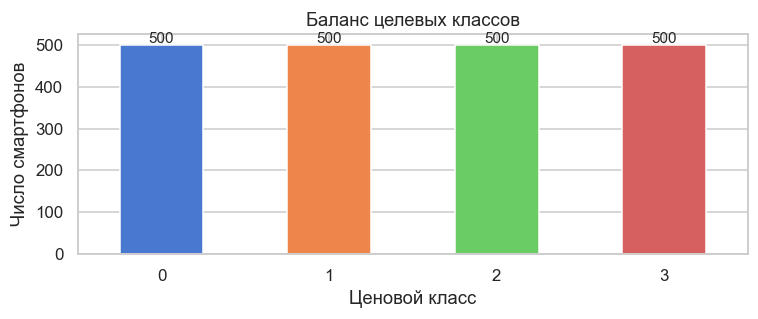

In [4]:
counts = df.price_range.value_counts().sort_index()
display(counts.rename("Количество").to_frame())
ax = counts.plot.bar(rot=0, figsize=(7, 3), color=sns.color_palette("muted", 4))
ax.set(xlabel="Ценовой класс", ylabel="Число смартфонов", title="Баланс целевых классов")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()
ANALYSIS["balance"] = (
    f"Численности классов 0–3: {counts.tolist()}, доли: {(counts / len(df)).round(3).tolist()}. "
    "Сбалансированность делает равноправное macro-усреднение естественным: "
    "F1-macro = (F1₀ + F1₁ + F1₂ + F1₃)/4. Базовая точность константного "
    f"предсказания наиболее частого класса равна {counts.max()/len(df):.3f}.")

### Интерпретация результатов

Численности классов 0–3: [500, 500, 500, 500], доли: [0.25, 0.25, 0.25, 0.25]. Сбалансированность делает равноправное macro-усреднение естественным: F1-macro = (F1₀ + F1₁ + F1₂ + F1₃)/4. Базовая точность константного предсказания наиболее частого класса равна 0.250.

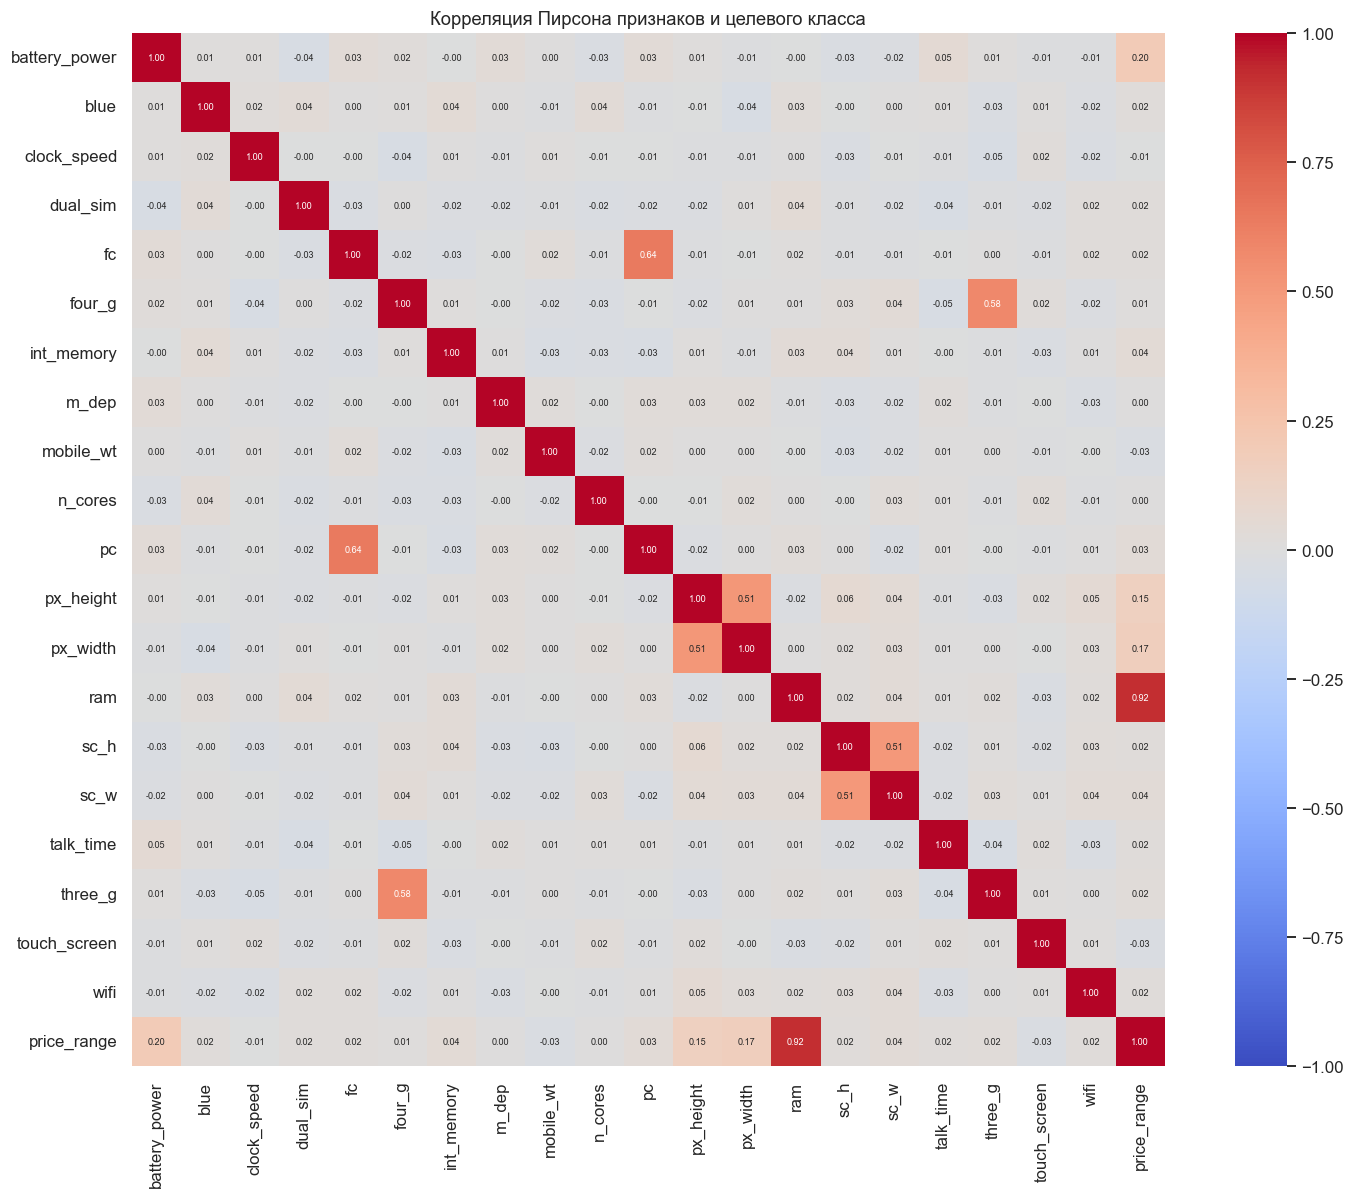

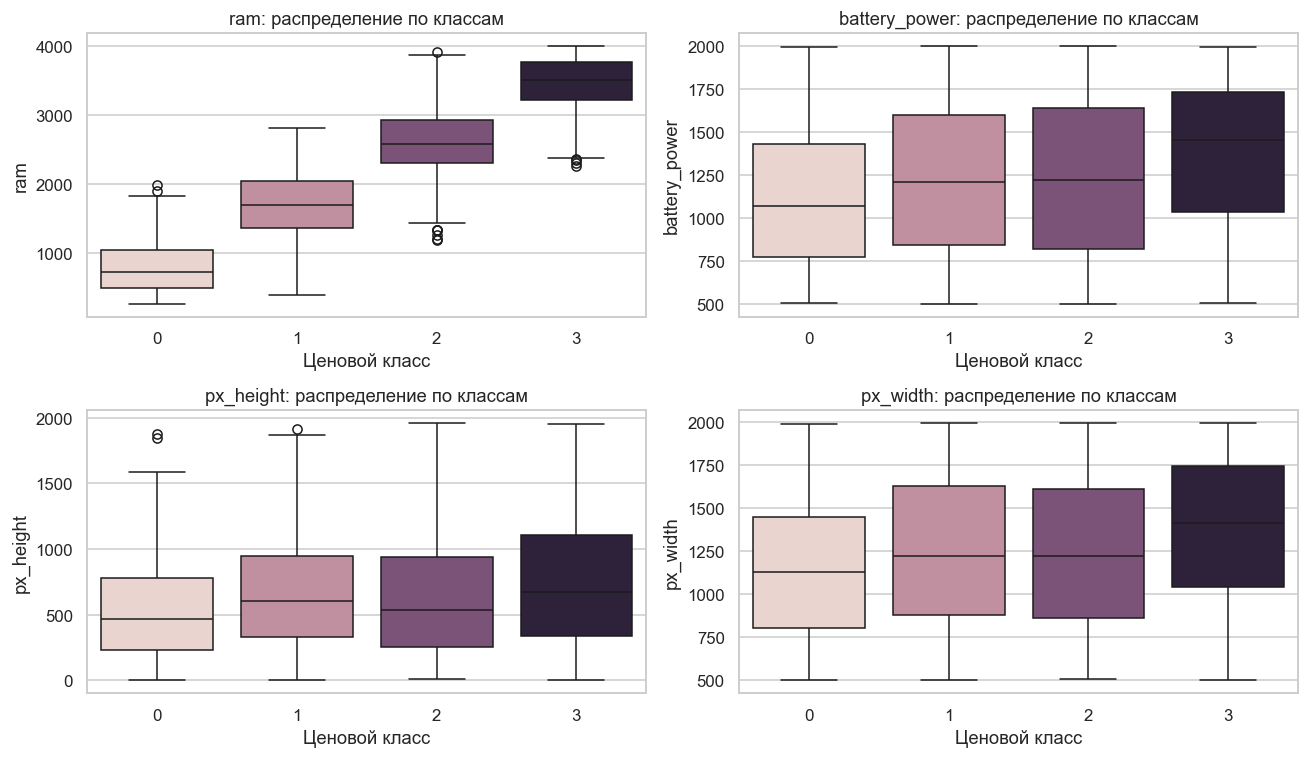

,r с price_range
ram,0.917046
battery_power,0.200723
px_width,0.165818
px_height,0.148858
int_memory,0.044435
sc_w,0.038711
pc,0.033599
touch_screen,-0.030411


In [5]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax,
            annot=True, fmt=".2f", annot_kws={"fontsize": 6}, square=True)
ax.set_title("Корреляция Пирсона признаков и целевого класса")
plt.tight_layout(); plt.show()
key_features = ["ram", "battery_power", "px_height", "px_width"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for feature, ax in zip(key_features, axes.flat):
    sns.boxplot(data=df, x="price_range", y=feature, hue="price_range", legend=False, ax=ax)
    ax.set(xlabel="Ценовой класс", ylabel=feature, title=f"{feature}: распределение по классам")
plt.tight_layout(); plt.show()
target_corr = corr.price_range.drop("price_range").sort_values(key=abs, ascending=False)
display(target_corr.head(8).rename("r с price_range").to_frame())
ANALYSIS["correlation"] = (
    "Линейные корреляции с номером сегмента: "
    + "; ".join(f"{c}: r={corr.loc[c, 'price_range']:.4f}" for c in key_features) + ". "
    f"Наибольшая абсолютная корреляция у {target_corr.index[0]} "
    f"(|r|={abs(target_corr.iloc[0]):.4f}). Увеличение RAM сопровождается сдвигом "
    "распределения к дорогим сегментам; остальные характеристики дополняют разделение. "
    "Корреляция с кодами 0–3 описывает порядковую ассоциацию, не доказывает причинность "
    "или нормальность условных распределений. EDA всей таблицы носит описательный характер; "
    "по нему не отбираются признаки и не изменяются сетки поиска.")

### Интерпретация результатов

Линейные корреляции с номером сегмента: ram: r=0.9170; battery_power: r=0.2007; px_height: r=0.1489; px_width: r=0.1658. Наибольшая абсолютная корреляция у ram (|r|=0.9170). Увеличение RAM сопровождается сдвигом распределения к дорогим сегментам; остальные характеристики дополняют разделение. Корреляция с кодами 0–3 описывает порядковую ассоциацию, не доказывает причинность или нормальность условных распределений. EDA всей таблицы носит описательный характер; по нему не отбираются признаки и не изменяются сетки поиска.

## 2. Предобработка и подготовка выборок

In [6]:
X = df[FEATURES]
y = df.price_range.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
standard_scaler = StandardScaler()
X_train_scaled = standard_scaler.fit_transform(X_train_imputed)
X_test_scaled = standard_scaler.transform(X_test_imputed)
minmax_scaler = MinMaxScaler(feature_range=(0, 1), clip=True)
X_train_minmax = minmax_scaler.fit_transform(X_train_imputed)
X_test_minmax = minmax_scaler.transform(X_test_imputed)
assert not set(X_train.index) & set(X_test.index)
assert X_train_minmax.min() >= 0 and X_test_minmax.min() >= 0
assert X_train_minmax.max() <= 1 and X_test_minmax.max() <= 1
y_test_bin = label_binarize(y_test, classes=CLASSES)
display(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                      "test": y_test.value_counts().sort_index()}))
display(pd.DataFrame({"ветка": ["Standard train", "Standard test", "MinMax train", "MinMax test"],
    "min": [a.min() for a in [X_train_scaled, X_test_scaled, X_train_minmax, X_test_minmax]],
    "max": [a.max() for a in [X_train_scaled, X_test_scaled, X_train_minmax, X_test_minmax]]}))
ANALYSIS["split"] = (
    f"Обучающая часть: {len(X_train)}, тестовая: {len(X_test)} объектов; "
    f"по классам в train — {y_train.value_counts().sort_index().tolist()}, "
    f"в test — {y_test.value_counts().sort_index().tolist()}. "
    "Стратификация сохраняет доли. StandardScaler использует z=(x−μ_train)/σ_train, "
    "MinMaxScaler — (x−min_train)/(max_train−min_train). Параметр clip=True удерживает "
    "новые экстремумы теста в [0,1], не обучаясь на них; это предотвращает отрицательные "
    "значения для MultinomialNB и ComplementNB. Клиппинг может потерять информацию "
    "о значениях вне обучающего диапазона. В GridSearchCV используются сырые X_train "
    "и Pipeline: предварительно масштабированная полная train-часть в CV не передаётся.")

,train,test
price_range,,
0,400,100
1,400,100
2,400,100
3,400,100


,ветка,min,max
0,Standard train,-1.788708,3.384686
1,Standard test,-1.788708,3.154082
2,MinMax train,0.000000,1.000000
3,MinMax test,0.000000,1.000000


### Интерпретация результатов

Обучающая часть: 1600, тестовая: 400 объектов; по классам в train — [400, 400, 400, 400], в test — [100, 100, 100, 100]. Стратификация сохраняет доли. StandardScaler использует z=(x−μ_train)/σ_train, MinMaxScaler — (x−min_train)/(max_train−min_train). Параметр clip=True удерживает новые экстремумы теста в [0,1], не обучаясь на них; это предотвращает отрицательные значения для MultinomialNB и ComplementNB. Клиппинг может потерять информацию о значениях вне обучающего диапазона. В GridSearchCV используются сырые X_train и Pipeline: предварительно масштабированная полная train-часть в CV не передаётся.

In [7]:
def metrics(y_true, pred, proba):
    assert proba.shape == (len(y_true), 4)
    assert np.isfinite(proba).all() and np.all(proba >= 0)
    assert np.allclose(proba.sum(axis=1), 1, atol=1e-5)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "Recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "F1-macro": f1_score(y_true, pred, average="macro", zero_division=0),
            "ROC-AUC": roc_auc_score(label_binarize(y_true, classes=CLASSES), proba,
                                     multi_class="ovr", average="macro")}

def evaluate(model, features):
    assert np.array_equal(model.classes_, CLASSES), "Неверный порядок столбцов вероятностей"
    return metrics(y_test, model.predict(features), model.predict_proba(features))

def plot_roc(y_true, proba, ax, title):
    truth = label_binarize(y_true, classes=CLASSES)
    grid = np.linspace(0, 1, 2001)
    tprs = []
    areas = []
    for i in CLASSES:
        fpr, tpr, _ = roc_curve(truth[:, i], proba[:, i])
        areas.append(auc(fpr, tpr))
        tprs.append(np.interp(grid, fpr, tpr))
        ax.plot(fpr, tpr, label=f"Класс {i}, AUC={areas[-1]:.3f}")
    macro = float(np.mean(areas))
    ax.plot(grid, np.mean(tprs, axis=0), "k--", lw=2, label=f"Macro, AUC={macro:.3f}")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set(xlabel="FPR", ylabel="TPR", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
    return areas

ANALYSIS["helpers"] = (
    "Единая оценка включает 5 метрик. Precision, Recall и F1 усредняются по 4 классам "
    "с равными весами; ROC-AUC — среднее четырёх OvR-AUC по вероятностям, а не жёстким "
    "меткам. Проверяются порядок классов, конечность и нормировка вероятностей. "
    "Пунктирная macro-ROC усредняет интерполированные TPR при одинаковом FPR; её подпись "
    "содержит точное среднее AUC отдельных классов. Высокий AUC отражает ранжирование "
    "и может сочетаться с невысоким F1 при ошибках выбора самого вероятного класса.")

### Интерпретация результатов

Единая оценка включает 5 метрик. Precision, Recall и F1 усредняются по 4 классам с равными весами; ROC-AUC — среднее четырёх OvR-AUC по вероятностям, а не жёстким меткам. Проверяются порядок классов, конечность и нормировка вероятностей. Пунктирная macro-ROC усредняет интерполированные TPR при одинаковом FPR; её подпись содержит точное среднее AUC отдельных классов. Высокий AUC отражает ранжирование и может сочетаться с невысоким F1 при ошибках выбора самого вероятного класса.

## 3. Внутреннее сравнение семейства Naive Bayes

,Accuracy,Precision,Recall,F1-macro,ROC-AUC
GaussianNB,0.8100,0.8113,0.8100,0.8105,0.9506
MultinomialNB,0.5975,0.6201,0.5975,0.6064,0.7969
ComplementNB,0.5400,0.5461,0.5400,0.4493,0.7866
BernoulliNB,0.5400,0.5286,0.5400,0.5313,0.8306


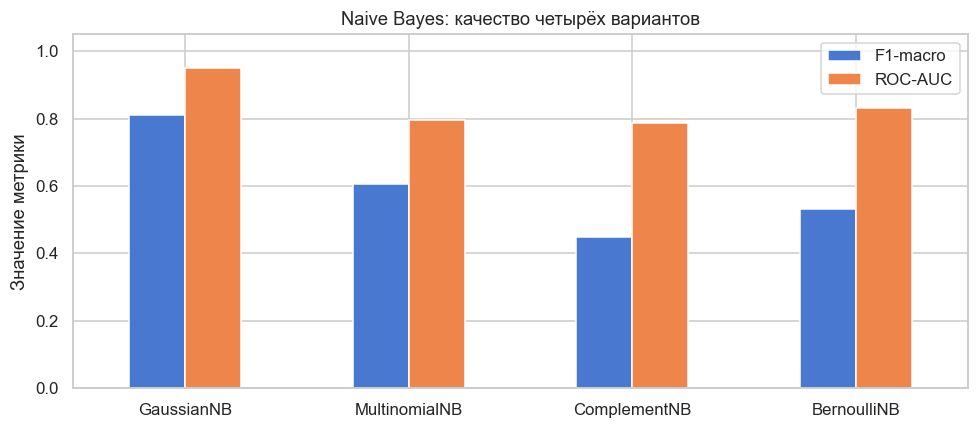

In [8]:
nb_models = {"GaussianNB": GaussianNB(), "MultinomialNB": MultinomialNB(),
             "ComplementNB": ComplementNB(), "BernoulliNB": BernoulliNB(binarize=0.5)}
nb_rows = {}
for name, model in nb_models.items():
    a, b = (X_train_scaled, X_test_scaled) if name == "GaussianNB" else (X_train_minmax, X_test_minmax)
    model.fit(a, y_train)
    nb_rows[name] = evaluate(model, b)
nb_table = pd.DataFrame(nb_rows).T
display(nb_table.round(4))
nb_table[["F1-macro", "ROC-AUC"]].plot.bar(figsize=(9, 4), rot=0)
plt.title("Naive Bayes: качество четырёх вариантов")
plt.ylabel("Значение метрики"); plt.ylim(0, 1.05)
plt.legend(); plt.tight_layout(); plt.show()
ANALYSIS["bayes"] = (
    "F1-macro по вариантам: " + "; ".join(f"{n}={nb_table.loc[n, 'F1-macro']:.4f}" for n in nb_table.index)
    + f". GaussianNB: ROC-AUC={nb_table.loc['GaussianNB', 'ROC-AUC']:.4f}. "
    "GaussianNB моделирует отдельную условную гауссиану каждого признака; это полезное "
    "приближение для числовых характеристик, но не доказательство их нормальности. "
    "MultinomialNB и ComplementNB ожидают неотрицательные частоты: перевод RAM и ёмкости "
    "в [0,1] обеспечивает допустимость вычислений, но не соответствие вероятностной модели. "
    "BernoulliNB при пороге 0.5 теряет различия внутри половин диапазона. По условию "
    "GaussianNB представляет семейство в дальнейшем сравнении; этот выбор не перенастраивается по тесту.")

### Интерпретация результатов

F1-macro по вариантам: GaussianNB=0.8105; MultinomialNB=0.6064; ComplementNB=0.4493; BernoulliNB=0.5313. GaussianNB: ROC-AUC=0.9506. GaussianNB моделирует отдельную условную гауссиану каждого признака; это полезное приближение для числовых характеристик, но не доказательство их нормальности. MultinomialNB и ComplementNB ожидают неотрицательные частоты: перевод RAM и ёмкости в [0,1] обеспечивает допустимость вычислений, но не соответствие вероятностной модели. BernoulliNB при пороге 0.5 теряет различия внутри половин диапазона. По условию GaussianNB представляет семейство в дальнейшем сравнении; этот выбор не перенастраивается по тесту.

## 4. Базовое обучение пяти методов

In [9]:
base_models = {"GaussianNB": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "LDA": LinearDiscriminantAnalysis(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "kNN": KNeighborsClassifier()}
base_rows, base_times = {}, {}
for name, model in base_models.items():
    start = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    base_times[name] = time.perf_counter() - start
    base_rows[name] = evaluate(model, X_test_scaled)
baseline = pd.DataFrame(base_rows).T
display(baseline.sort_values("F1-macro", ascending=False).round(4))
ANALYSIS["baseline"] = (
    "Базовые F1-macro: " + "; ".join(f"{n}={baseline.loc[n, 'F1-macro']:.4f}" for n in baseline.index)
    + ". LDA строит линейные границы с общей внутриклассовой ковариацией; SVC по умолчанию "
    "использует RBF-ядро. Для SVC включена probability=True: вероятности получаются через "
    "внутреннюю калибровку Платта, что увеличивает время обучения; predict и argmax "
    "predict_proba могут различаться. kNN вычисляет расстояния по всем 20 стандартизованным "
    "характеристикам, поэтому слабые признаки могут мешать локальному разделению. "
    f"Неограниченное дерево имеет глубину {base_models['DecisionTree'].get_depth()} "
    f"и train F1={f1_score(y_train, base_models['DecisionTree'].predict(X_train_scaled), average='macro'):.4f}; "
    "разрыв с тестом указывает на высокую гибкость и возможное переобучение.")

,Accuracy,Precision,Recall,F1-macro,ROC-AUC
LDA,0.955,0.9556,0.955,0.9552,0.9958
SVM,0.895,0.8969,0.895,0.8956,0.9833
DecisionTree,0.830,0.8319,0.830,0.8302,0.8867
GaussianNB,0.810,0.8113,0.810,0.8105,0.9506
kNN,0.500,0.5211,0.500,0.5054,0.7697


### Интерпретация результатов

Базовые F1-macro: GaussianNB=0.8105; DecisionTree=0.8302; LDA=0.9552; SVM=0.8956; kNN=0.5054. LDA строит линейные границы с общей внутриклассовой ковариацией; SVC по умолчанию использует RBF-ядро. Для SVC включена probability=True: вероятности получаются через внутреннюю калибровку Платта, что увеличивает время обучения; predict и argmax predict_proba могут различаться. kNN вычисляет расстояния по всем 20 стандартизованным характеристикам, поэтому слабые признаки могут мешать локальному разделению. Неограниченное дерево имеет глубину 11 и train F1=1.0000; разрыв с тестом указывает на высокую гибкость и возможное переобучение.

## 5. Визуализация качества базовых моделей

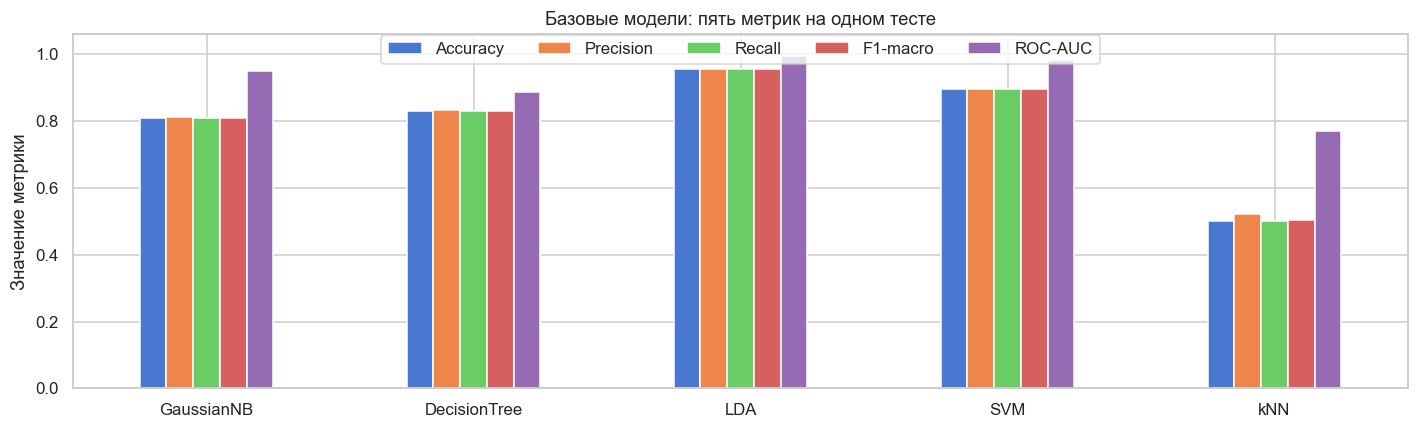

In [10]:
baseline[METRICS].plot.bar(figsize=(13, 4), rot=0)
plt.title("Базовые модели: пять метрик на одном тесте")
plt.ylabel("Значение метрики"); plt.ylim(0, 1.06)
plt.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.show()
best_base = baseline["F1-macro"].idxmax()
worst_base = baseline["F1-macro"].idxmin()
ANALYSIS["base_bar"] = (
    f"Наибольший базовый F1-macro у {best_base}: {baseline.loc[best_base, 'F1-macro']:.4f}; "
    f"наименьший у {worst_base}: {baseline.loc[worst_base, 'F1-macro']:.4f}. "
    f"Разность равна {100*(baseline.loc[best_base, 'F1-macro']-baseline.loc[worst_base, 'F1-macro']):.2f} п.п. "
    "Accuracy и macro-Recall здесь совпадают, поскольку каждый истинный класс представлен "
    "ровно 100 объектами. F1 дополнительно учитывает ложноположительные предсказания. "
    "Выбор лучшей/худшей модели в этом разделе служит диагностике ошибок на фиксированном "
    "тесте; подбор гиперпараметров далее использует только CV обучающей части.")

### Интерпретация результатов

Наибольший базовый F1-macro у LDA: 0.9552; наименьший у kNN: 0.5054. Разность равна 44.98 п.п. Accuracy и macro-Recall здесь совпадают, поскольку каждый истинный класс представлен ровно 100 объектами. F1 дополнительно учитывает ложноположительные предсказания. Выбор лучшей/худшей модели в этом разделе служит диагностике ошибок на фиксированном тесте; подбор гиперпараметров далее использует только CV обучающей части.

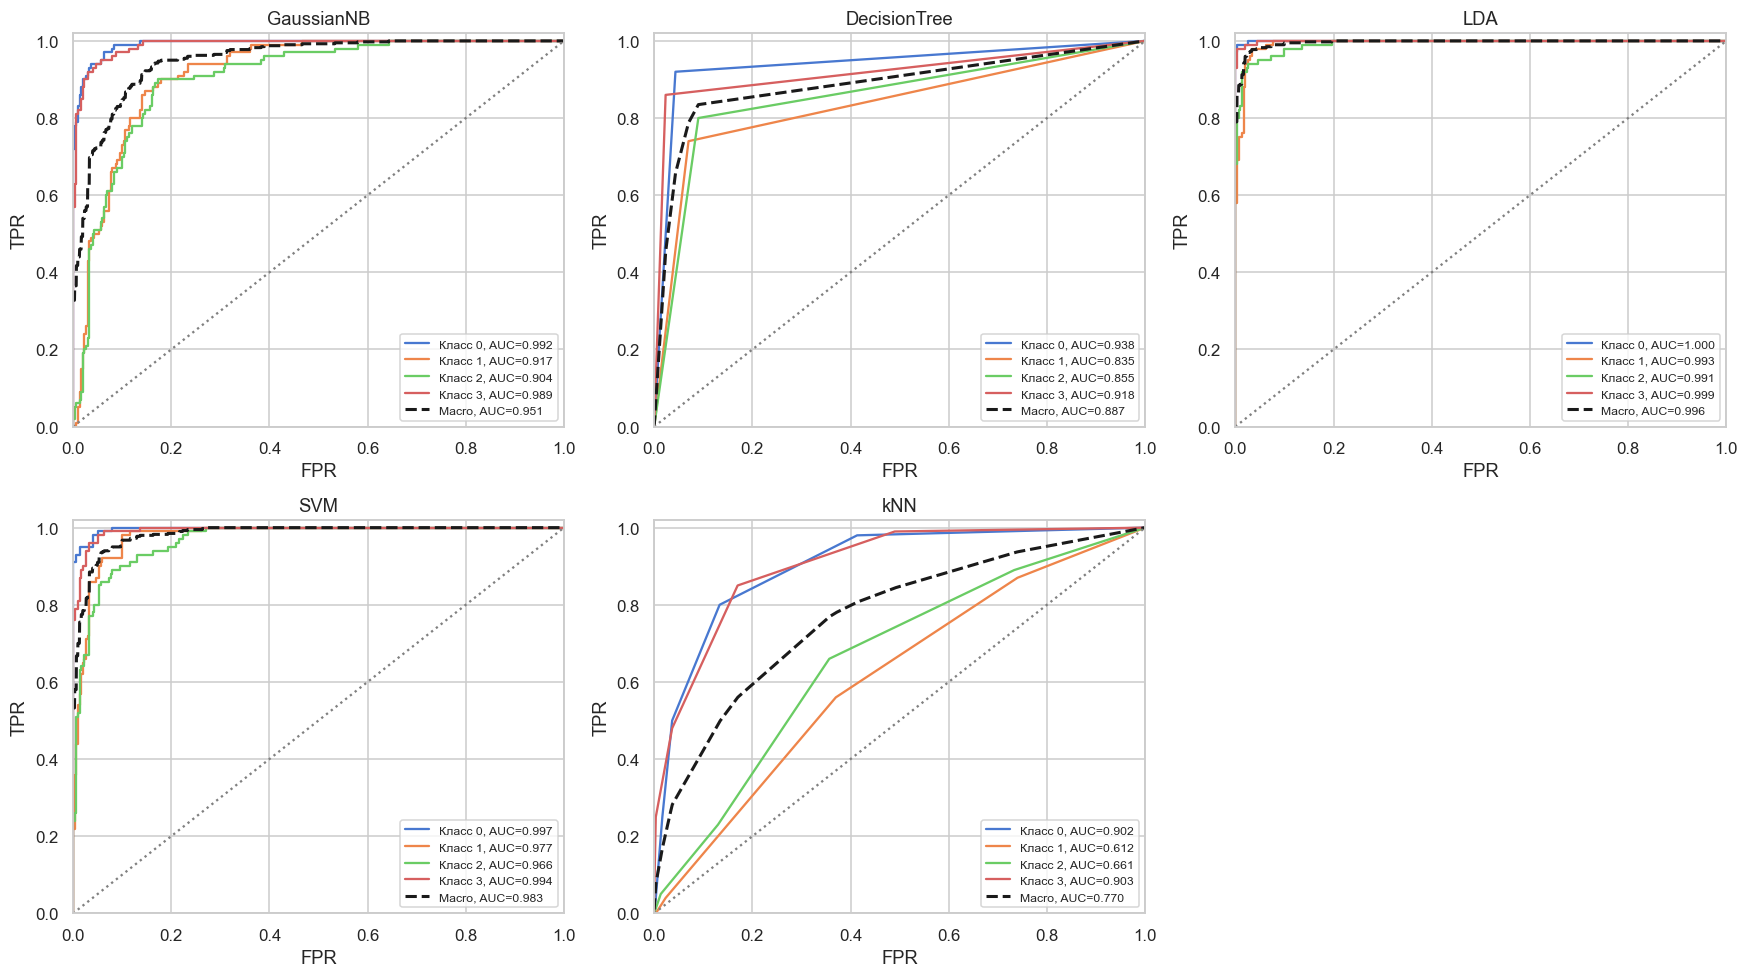

,Класс 0,Класс 1,Класс 2,Класс 3
GaussianNB,0.9921,0.9172,0.9036,0.9893
DecisionTree,0.9383,0.8350,0.8550,0.9183
LDA,0.9997,0.9933,0.9911,0.9992
SVM,0.9971,0.9766,0.9659,0.9936
kNN,0.9023,0.6120,0.6615,0.9032


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
base_auc = {}
for (name, model), ax in zip(base_models.items(), axes.flat):
    base_auc[name] = plot_roc(y_test, model.predict_proba(X_test_scaled), ax, name)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()
display(pd.DataFrame(base_auc, index=[f"Класс {c}" for c in CLASSES]).T.round(4))
ANALYSIS["base_roc"] = (
    "Поклассовые AUC лучшей базовой модели " + best_base + ": "
    + "; ".join(f"{c}={a:.4f}" for c, a in enumerate(base_auc[best_base])) + ". "
    f"У {worst_base} диапазон AUC равен {min(base_auc[worst_base]):.4f}–{max(base_auc[worst_base]):.4f}. "
    "Крайние сегменты могут быть проще для отделения из-за одного соседнего ценового "
    "сегмента, а промежуточные имеют две соседние границы. OvR-кривая сравнивает класс "
    "со всеми остальными; её форма сама по себе не определяет, между какими парами "
    "классов происходят ошибки. Поэтому гипотеза о смежных ошибках проверяется матрицами ниже, "
    "а идеальная разделимость всех моделей заранее не предполагается.")

### Интерпретация результатов

Поклассовые AUC лучшей базовой модели LDA: 0=0.9997; 1=0.9933; 2=0.9911; 3=0.9992. У kNN диапазон AUC равен 0.6120–0.9032. Крайние сегменты могут быть проще для отделения из-за одного соседнего ценового сегмента, а промежуточные имеют две соседние границы. OvR-кривая сравнивает класс со всеми остальными; её форма сама по себе не определяет, между какими парами классов происходят ошибки. Поэтому гипотеза о смежных ошибках проверяется матрицами ниже, а идеальная разделимость всех моделей заранее не предполагается.

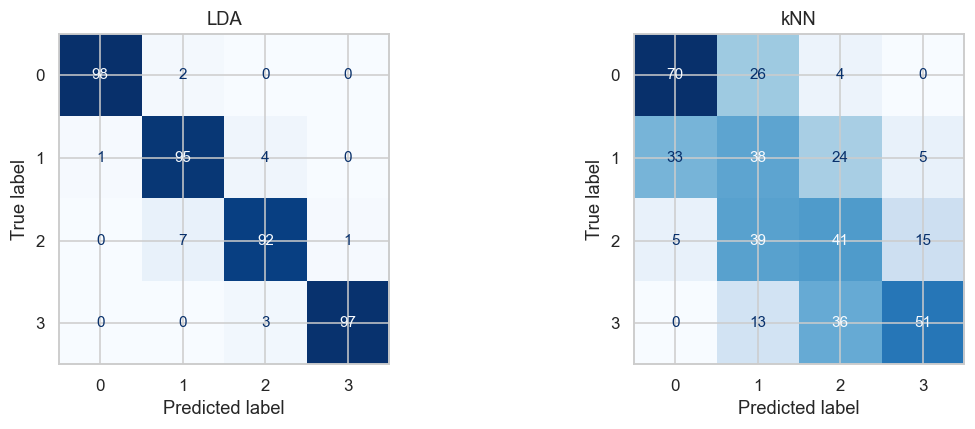

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm_stats = {}
for name, ax in zip([best_base, worst_base], axes):
    pred = base_models[name].predict(X_test_scaled)
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    errors = int((pred != y_test).sum())
    adjacent = int((np.abs(pred - y_test.to_numpy()) == 1).sum())
    cm_stats[name] = (errors, adjacent, int(cm[0,3] + cm[3,0]), int(cm[1,2]+cm[2,1]))
plt.tight_layout(); plt.show()
ANALYSIS["base_cm"] = "\n\n".join(
    f"**{n}:** ошибок {v[0]}/{len(y_test)}; между соседними сегментами — {v[1]} "
    f"({100*v[1]/max(v[0],1):.1f}% ошибок), между 0 и 3 — {v[2]}, между 1 и 2 — {v[3]}. "
    "Строка соответствует истинному классу, столбец — предсказанному. Смежные ошибки "
    "согласуются с перекрытием характеристик возле границ ценовых диапазонов; "
    "ошибки между 0 и 3 означают более сильное смешение. Эти числа описывают наблюдения, "
    "а не навязывают ожидаемый образец из методички."
    for n, v in cm_stats.items())

### Интерпретация результатов

**LDA:** ошибок 18/400; между соседними сегментами — 18 (100.0% ошибок), между 0 и 3 — 0, между 1 и 2 — 11. Строка соответствует истинному классу, столбец — предсказанному. Смежные ошибки согласуются с перекрытием характеристик возле границ ценовых диапазонов; ошибки между 0 и 3 означают более сильное смешение. Эти числа описывают наблюдения, а не навязывают ожидаемый образец из методички.

**kNN:** ошибок 200/400; между соседними сегментами — 173 (86.5% ошибок), между 0 и 3 — 0, между 1 и 2 — 63. Строка соответствует истинному классу, столбец — предсказанному. Смежные ошибки согласуются с перекрытием характеристик возле границ ценовых диапазонов; ошибки между 0 и 3 означают более сильное смешение. Эти числа описывают наблюдения, а не навязывают ожидаемый образец из методички.

## 6. Настройка гиперпараметров: пять фолдов, F1-macro

Используется `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
Каждый кандидат — `Pipeline(SimpleImputer, StandardScaler, classifier)`.
На графике меняется один параметр, остальные фиксируются значениями лучшего CV-кандидата;
для SVM отдельно показаны три ядра с лучшими параметрами своего ядра. Значения берутся
из уже вычисленных `cv_results_`, поэтому повторное обучение ради графиков не требуется.
Полосы — ±1 стандартное отклонение по фолдам; это не доверительный интервал.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Keep a small shared-memory worker pool: full SVC probability calibration is retained.
from joblib import parallel_backend
N_JOBS = min(4, os.cpu_count() or 1)
searches, search_times, tuned_models = {}, {}, {}
def run_search(name, classifier, grid):
    pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler()), ("model", classifier)])
    search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=cv,
                          n_jobs=N_JOBS, return_train_score=True, error_score="raise")
    start = time.perf_counter()
    with parallel_backend("threading", n_jobs=N_JOBS):
        search.fit(X_train, y_train)
    search_times[name] = time.perf_counter() - start
    searches[name] = search
    tuned_models[name] = search.best_estimator_
    print(name, "кандидатов:", len(search.cv_results_["params"]),
          "лучший CV F1:", round(search.best_score_, 5), "параметры:", search.best_params_)
    return search

def curve_rows(search, parameter, fixed=None):
    fixed = dict(search.best_params_) if fixed is None else dict(fixed)
    fixed.pop(parameter, None)
    result = search.cv_results_
    indices = [i for i, params in enumerate(result["params"])
               if parameter in params and all(params.get(k) == v for k, v in fixed.items())]
    assert indices, f"Пустая кривая: {parameter}, {fixed}"
    rows = pd.DataFrame({"x": [result["params"][i][parameter] for i in indices],
        "train": result["mean_train_score"][indices], "validation": result["mean_test_score"][indices],
        "train_std": result["std_train_score"][indices], "val_std": result["std_test_score"][indices]})
    return rows.sort_values("x")

def draw_curve(rows, ax, title, xlabel, log=False, prefix=""):
    x = rows.x.to_numpy(dtype=float)
    for col, std, style in [("train", "train_std", "--"), ("validation", "val_std", "-")]:
        line, = ax.plot(x, rows[col], style, marker=".", label=f"{prefix}{col}")
        ax.fill_between(x, rows[col]-rows[std], rows[col]+rows[std], alpha=0.09, color=line.get_color())
    if log:
        ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel="F1-macro", ylim=(0, 1.03))
    ax.legend(fontsize=8)

ANALYSIS["search_helpers"] = (
    f"Для всех пяти семейств используются одинаковые 5 стратифицированных фолдов "
    f"и до {N_JOBS} параллельных потоков. Критерий выбора — средний validation F1-macro. "
    "Импутер и скейлер обучаются независимо на каждом train-фолде; тест в поиск не входит. "
    "Валидационные кривые показывают срез полной сетки, а не максимум по разным скрытым "
    "настройкам в каждой точке. Финальный refit GridSearchCV обучает выбранный пайплайн "
    "на всех 1600 обучающих объектах. Лучший CV-score может иметь оптимистическое "
    "смещение из-за перебора; независимый тест даёт отдельную описательную оценку.")

### Интерпретация результатов

Для всех пяти семейств используются одинаковые 5 стратифицированных фолдов и до 4 параллельных потоков. Критерий выбора — средний validation F1-macro. Импутер и скейлер обучаются независимо на каждом train-фолде; тест в поиск не входит. Валидационные кривые показывают срез полной сетки, а не максимум по разным скрытым настройкам в каждой точке. Финальный refit GridSearchCV обучает выбранный пайплайн на всех 1600 обучающих объектах. Лучший CV-score может иметь оптимистическое смещение из-за перебора; независимый тест даёт отдельную описательную оценку.

GaussianNB кандидатов: 20 лучший CV F1: 0.81378 параметры: {'model__var_smoothing': np.float64(0.1)}


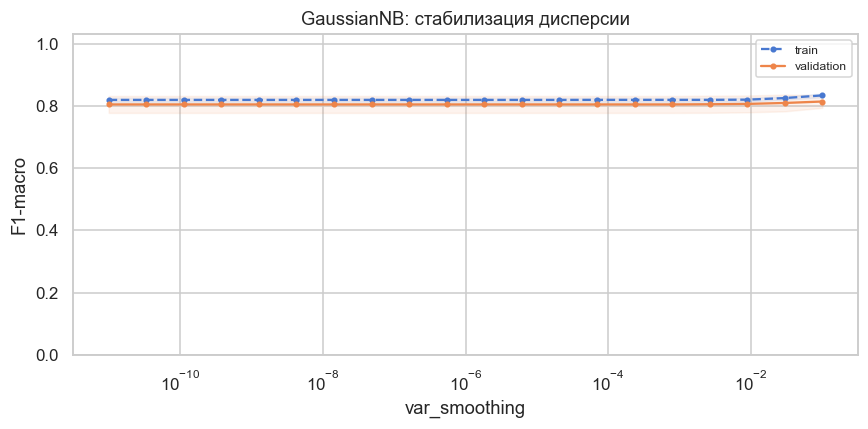

In [14]:
s = run_search("GaussianNB", GaussianNB(), {"model__var_smoothing": np.logspace(-11, -1, 20)})
rows_nb = curve_rows(s, "model__var_smoothing")
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_nb, ax, "GaussianNB: стабилизация дисперсии", "var_smoothing", log=True)
plt.tight_layout(); plt.show()
ANALYSIS["tune_nb"] = (
    f"Проверено {len(s.cv_results_['params'])} кандидатов × 5 фолдов. "
    f"Лучший var_smoothing={s.best_params_['model__var_smoothing']:.3g}, "
    f"CV F1={s.best_score_:.4f} ± {s.cv_results_['std_test_score'][s.best_index_]:.4f}. "
    "Добавка var_smoothing·max(var(X)) к дисперсиям защищает логарифмы плотностей "
    "от численной неустойчивости. Слишком большая добавка сглаживает межклассовые "
    "различия; слабая чувствительность на части диапазона означает устойчивость "
    "приближения, а не улучшение при каждом изменении регуляризации.")

### Интерпретация результатов

Проверено 20 кандидатов × 5 фолдов. Лучший var_smoothing=0.1, CV F1=0.8138 ± 0.0203. Добавка var_smoothing·max(var(X)) к дисперсиям защищает логарифмы плотностей от численной неустойчивости. Слишком большая добавка сглаживает межклассовые различия; слабая чувствительность на части диапазона означает устойчивость приближения, а не улучшение при каждом изменении регуляризации.

DecisionTree кандидатов: 160 лучший CV F1: 0.84859 параметры: {'model__criterion': 'entropy', 'model__max_depth': 9, 'model__min_samples_split': 20}


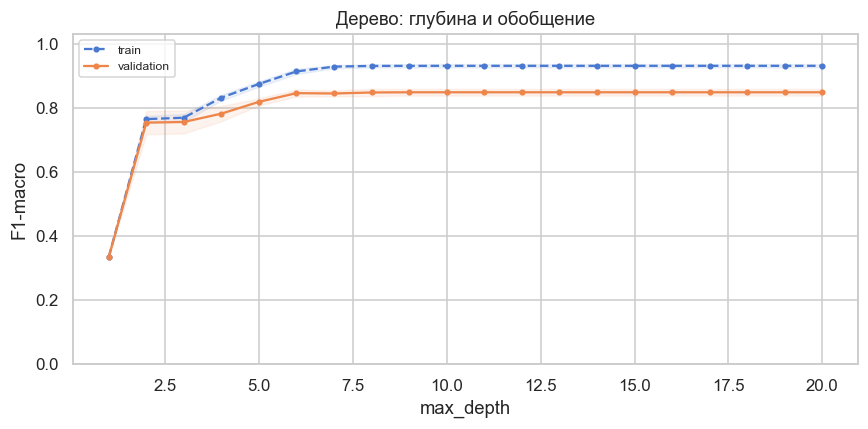

In [15]:
s = run_search("DecisionTree", DecisionTreeClassifier(random_state=RANDOM_STATE), {
    "model__max_depth": list(range(1, 21)), "model__min_samples_split": [2, 5, 10, 20],
    "model__criterion": ["gini", "entropy"]})
rows_tree = curve_rows(s, "model__max_depth")
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_tree, ax, "Дерево: глубина и обобщение", "max_depth")
plt.tight_layout(); plt.show()
perfect = rows_tree.loc[rows_tree.train >= 0.999999, "x"].tolist()
turning = str(int(perfect[0])) if perfect else "не достигнута в выбранном срезе"
last = rows_tree.iloc[-1]
ANALYSIS["tune_tree"] = (
    f"Перебрано {len(s.cv_results_['params'])} кандидатов (800 обучений CV). "
    f"Оптимум: {s.best_params_}; CV F1={s.best_score_:.4f}. "
    f"Первая глубина с усреднённым train F1≈1: {turning}. "
    f"При глубине 20 train F1={last.train:.4f}, validation F1={last.validation:.4f}, "
    f"разрыв={last.train-last.validation:.4f}. "
    "Рост глубины позволяет изолировать всё меньшие группы наблюдений; после насыщения "
    "валидационного качества дальнейшее повышение train-метрики описывает запоминание. "
    "Если min_samples_split ограничивает разбиения, полная единица может не достигаться "
    "даже при большой глубине, поэтому точка перегиба определяется фактически.")

### Интерпретация результатов

Перебрано 160 кандидатов (800 обучений CV). Оптимум: {'model__criterion': 'entropy', 'model__max_depth': 9, 'model__min_samples_split': 20}; CV F1=0.8486. Первая глубина с усреднённым train F1≈1: не достигнута в выбранном срезе. При глубине 20 train F1=0.9312, validation F1=0.8486, разрыв=0.0826. Рост глубины позволяет изолировать всё меньшие группы наблюдений; после насыщения валидационного качества дальнейшее повышение train-метрики описывает запоминание. Если min_samples_split ограничивает разбиения, полная единица может не достигаться даже при большой глубине, поэтому точка перегиба определяется фактически.

LDA кандидатов: 23 лучший CV F1: 0.93545 параметры: {'model__solver': 'svd'}


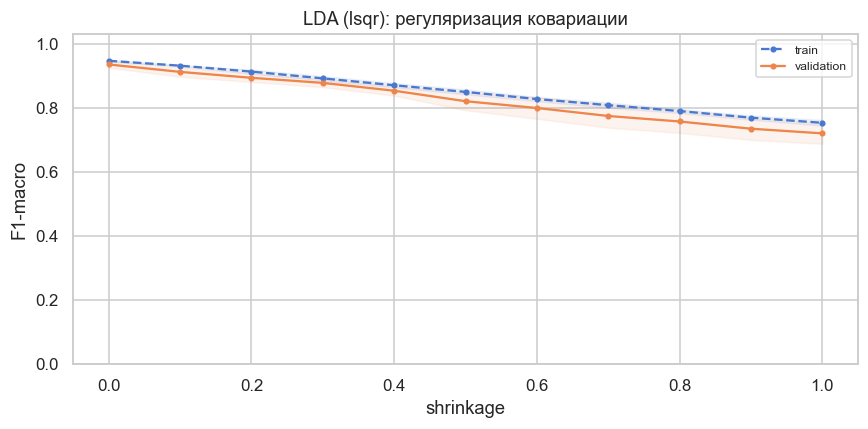

In [16]:
s = run_search("LDA", LinearDiscriminantAnalysis(), [
    {"model__solver": ["svd"]},
    {"model__solver": ["lsqr"], "model__shrinkage": np.linspace(0, 1, 11)},
    {"model__solver": ["eigen"], "model__shrinkage": np.linspace(0, 1, 11)}])
rows_lda = curve_rows(s, "model__shrinkage", {"model__solver": "lsqr"})
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_lda, ax, "LDA (lsqr): регуляризация ковариации", "shrinkage")
plt.tight_layout(); plt.show()
ANALYSIS["tune_lda"] = (
    f"Проверено {len(s.cv_results_['params'])} допустимых сочетания solver/shrinkage. "
    f"Лучшее: {s.best_params_}; CV F1={s.best_score_:.4f}. "
    f"Для lsqr при shrinkage=0 validation F1={rows_lda.iloc[0].validation:.4f}, "
    f"при shrinkage=1 — {rows_lda.iloc[-1].validation:.4f}. "
    "Shrinkage смешивает эмпирическую ковариацию с масштабированной единичной матрицей: "
    "Σλ=(1−λ)Σ+λ·tr(Σ)/p·I. Это снижает чувствительность к оценке зависимостей, "
    "но при большом λ может уничтожать полезную ковариационную структуру. "
    "Для svd параметр shrinkage не передаётся, что исключает несовместимые конфигурации.")

### Интерпретация результатов

Проверено 23 допустимых сочетания solver/shrinkage. Лучшее: {'model__solver': 'svd'}; CV F1=0.9354. Для lsqr при shrinkage=0 validation F1=0.9354, при shrinkage=1 — 0.7206. Shrinkage смешивает эмпирическую ковариацию с масштабированной единичной матрицей: Σλ=(1−λ)Σ+λ·tr(Σ)/p·I. Это снижает чувствительность к оценке зависимостей, но при большом λ может уничтожать полезную ковариационную структуру. Для svd параметр shrinkage не передаётся, что исключает несовместимые конфигурации.

SVM кандидатов: 60 лучший CV F1: 0.96496 параметры: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}


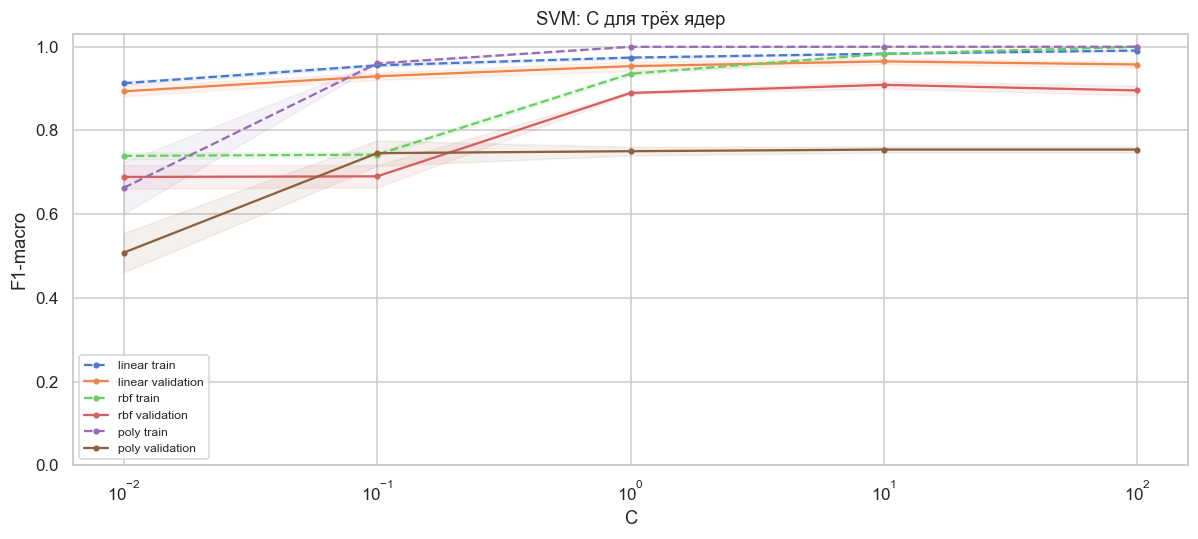

In [17]:
s = run_search("SVM", SVC(probability=True, random_state=RANDOM_STATE), {
    "model__C": [0.01, 0.1, 1, 10, 100], "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.01, 0.1]})
fig, ax = plt.subplots(figsize=(11, 5))
kernel_best = {}
for kernel in ["linear", "rbf", "poly"]:
    ids = [i for i,p in enumerate(s.cv_results_["params"]) if p["model__kernel"] == kernel]
    best_i = max(ids, key=lambda i: s.cv_results_["mean_test_score"][i])
    fixed = s.cv_results_["params"][best_i]
    rows = curve_rows(s, "model__C", fixed)
    draw_curve(rows, ax, "SVM: C для трёх ядер", "C", log=True, prefix=f"{kernel} ")
    kernel_best[kernel] = float(s.cv_results_["mean_test_score"][best_i])
plt.tight_layout(); plt.show()
ANALYSIS["tune_svm"] = (
    f"Полная сетка содержит {len(s.cv_results_['params'])} кандидатов; gamma для linear "
    "не влияет на решение и сохранена в сетке для буквального сравнения заданных сочетаний. "
    f"Лучшее: {s.best_params_}; CV F1={s.best_score_:.4f}. Лучшие CV F1 по ядрам: "
    + "; ".join(f"{k}={v:.4f}" for k,v in kernel_best.items()) + ". "
    "C задаёт штраф за нарушения зазора: малое значение усиливает регуляризацию, "
    "большое допускает более сложное разделение. Конкурентоспособность linear согласуется "
    "с сильным порядковым сигналом RAM и почти линейными границами в комбинации признаков. "
    "Преимущество нелинейного ядра следует оценивать по фактическому CV, а не предполагать. "
    "Калибровка вероятностей включена во всех кандидатах; F1 оценивается по predict.")

### Интерпретация результатов

Полная сетка содержит 60 кандидатов; gamma для linear не влияет на решение и сохранена в сетке для буквального сравнения заданных сочетаний. Лучшее: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}; CV F1=0.9650. Лучшие CV F1 по ядрам: linear=0.9650; rbf=0.9090; poly=0.7543. C задаёт штраф за нарушения зазора: малое значение усиливает регуляризацию, большое допускает более сложное разделение. Конкурентоспособность linear согласуется с сильным порядковым сигналом RAM и почти линейными границами в комбинации признаков. Преимущество нелинейного ядра следует оценивать по фактическому CV, а не предполагать. Калибровка вероятностей включена во всех кандидатах; F1 оценивается по predict.

kNN кандидатов: 160 лучший CV F1: 0.68085 параметры: {'model__metric': 'manhattan', 'model__n_neighbors': 39, 'model__weights': 'distance'}


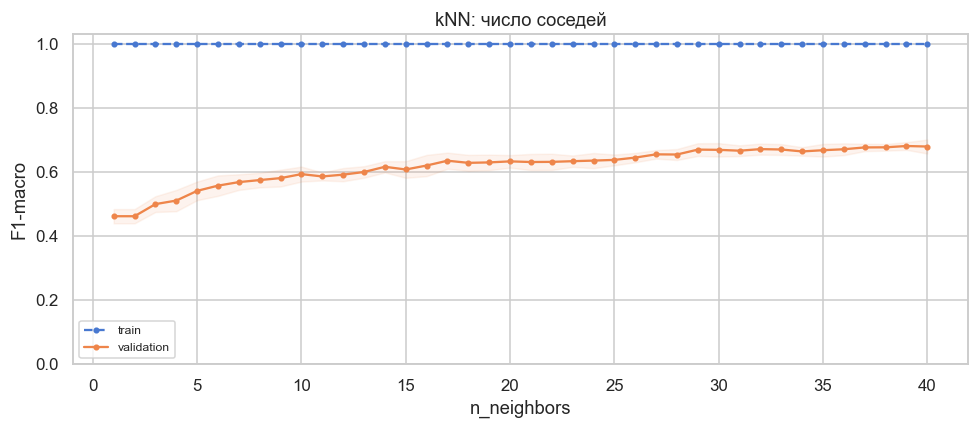

In [18]:
s = run_search("kNN", KNeighborsClassifier(), {
    "model__n_neighbors": list(range(1, 41)), "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]})
rows_knn = curve_rows(s, "model__n_neighbors")
fig, ax = plt.subplots(figsize=(9, 4))
draw_curve(rows_knn, ax, "kNN: число соседей", "n_neighbors")
plt.tight_layout(); plt.show()
knn_result = s.cv_results_
def best_knn_with(**kwargs):
    return max(knn_result["mean_test_score"][i] for i,p in enumerate(knn_result["params"])
               if all(p["model__"+k] == v for k,v in kwargs.items()))
metric_delta = best_knn_with(metric="manhattan") - best_knn_with(metric="euclidean")
weight_delta = best_knn_with(weights="distance") - best_knn_with(weights="uniform")
ANALYSIS["tune_knn"] = (
    f"Проверено {len(s.cv_results_['params'])} кандидатов, оптимум {s.best_params_}; "
    f"CV F1={s.best_score_:.4f}. В выбранном срезе при k=1 train F1={rows_knn.iloc[0].train:.4f}, "
    f"validation F1={rows_knn.iloc[0].validation:.4f}; при k=40 validation F1={rows_knn.iloc[-1].validation:.4f}. "
    "Малые k чувствительны к отдельным объектам, большие сглаживают соседства и увеличивают "
    "смещение. При weights='distance' train F1 может оставаться 1 из-за нулевого расстояния "
    "до самого объекта: это свойство resubstitution, а не доказательство хорошего обобщения. "
    f"Разница лучших CV F1 для manhattan−euclidean: {100*metric_delta:+.2f} п.п.; "
    f"distance−uniform: {100*weight_delta:+.2f} п.п. Это сравнение оптимумов подрешёток, "
    "не изолированный причинный эффект параметра. Отрицательное изменение не трактуется как прирост.")

### Интерпретация результатов

Проверено 160 кандидатов, оптимум {'model__metric': 'manhattan', 'model__n_neighbors': 39, 'model__weights': 'distance'}; CV F1=0.6809. В выбранном срезе при k=1 train F1=1.0000, validation F1=0.4617; при k=40 validation F1=0.6792. Малые k чувствительны к отдельным объектам, большие сглаживают соседства и увеличивают смещение. При weights='distance' train F1 может оставаться 1 из-за нулевого расстояния до самого объекта: это свойство resubstitution, а не доказательство хорошего обобщения. Разница лучших CV F1 для manhattan−euclidean: +7.09 п.п.; distance−uniform: +1.02 п.п. Это сравнение оптимумов подрешёток, не изолированный причинный эффект параметра. Отрицательное изменение не трактуется как прирост.

In [19]:
tuned = pd.DataFrame({n: evaluate(m, X_test) for n,m in tuned_models.items()}).T
comparison_rows = []
for name in baseline.index:
    for metric in METRICS:
        before, after = baseline.loc[name, metric], tuned.loc[name, metric]
        comparison_rows.append({"Модель": name, "Метрика": metric, "До": before, "После": after,
            "Изменение, п.п.": 100*(after-before), "Относительное, %": 100*(after-before)/before})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
display(pd.DataFrame({"CV F1": {n:s.best_score_ for n,s in searches.items()},
                      "Время поиска, с": search_times}).round(4))
ANALYSIS["tuning_summary"] = (
    "Изменение тестового F1-macro: "
    + "; ".join(f"{n}: {baseline.loc[n,'F1-macro']:.4f} → {tuned.loc[n,'F1-macro']:.4f} "
                 f"({100*(tuned.loc[n,'F1-macro']-baseline.loc[n,'F1-macro']):+.2f} п.п.)" for n in baseline.index)
    + ". Положительное изменение CV не гарантирует прироста на единственной тестовой "
    "выборке из 400 объектов. Процентные пункты равны 100·(после−до), относительный "
    "процент — 100·(после−до)/до; эти величины разделены в таблице. Наблюдаемые отрицательные "
    "дельты сохранены. Тест не используется для выбора между базовой и настроенной конфигурациями.")

,Модель,Метрика,До,После,"Изменение, п.п.","Относительное, %"
0,GaussianNB,Accuracy,0.8100,0.8225,1.2500,1.5432
1,GaussianNB,Precision,0.8113,0.8208,0.9484,1.1689
2,GaussianNB,Recall,0.8100,0.8225,1.2500,1.5432
3,GaussianNB,F1-macro,0.8105,0.8214,1.0953,1.3515
4,GaussianNB,ROC-AUC,0.9506,0.9524,0.1850,0.1946
5,DecisionTree,Accuracy,0.8300,0.8750,4.5000,5.4217
6,DecisionTree,Precision,0.8319,0.8738,4.1926,5.0399
7,DecisionTree,Recall,0.8300,0.8750,4.5000,5.4217
8,DecisionTree,F1-macro,0.8302,0.8742,4.3995,5.2995
9,DecisionTree,ROC-AUC,0.8867,0.9670,8.0317,9.0583


,CV F1,"Время поиска, с"
GaussianNB,0.8138,2.9792
DecisionTree,0.8486,23.2284
LDA,0.9354,3.8998
SVM,0.9650,69.2835
kNN,0.6809,91.5613


### Интерпретация результатов

Изменение тестового F1-macro: GaussianNB: 0.8105 → 0.8214 (+1.10 п.п.); DecisionTree: 0.8302 → 0.8742 (+4.40 п.п.); LDA: 0.9552 → 0.9552 (+0.00 п.п.); SVM: 0.8956 → 0.9750 (+7.94 п.п.); kNN: 0.5054 → 0.7306 (+22.52 п.п.). Положительное изменение CV не гарантирует прироста на единственной тестовой выборке из 400 объектов. Процентные пункты равны 100·(после−до), относительный процент — 100·(после−до)/до; эти величины разделены в таблице. Наблюдаемые отрицательные дельты сохранены. Тест не используется для выбора между базовой и настроенной конфигурациями.

## 7. TensorFlow / Keras: архитектура, регуляризация и learning rate

Внешний train дополнительно стратифицирован на 1280 объектов для обучения и 320 для
валидации. В этой серии импутер и StandardScaler обучаются **только на 1280 объектах**.
Четыре группы экспериментов включают пять уникальных запусков: Exp 1, Exp 2, Exp 3 и
Exp 4 с двумя дополнительными learning rate; контроль `lr=0.001` в Exp 4 совпадает с
Exp 1 по архитектуре, seed, данным и числу эпох и используется повторно.

Ни переобучение глубокой сети, ни превосходство регуляризованной архитектуры не
предполагаются заранее. Победитель выбирается по минимальному validation loss;
затем сеть с этой архитектурой обучается с нуля на всём внешнем train в течение
выбранного числа эпох. Тест впервые используется после этого выбора.

In [20]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
nn_imputer = SimpleImputer(strategy="median")
nn_scaler = StandardScaler()
X_fit_scaled = nn_scaler.fit_transform(nn_imputer.fit_transform(X_fit)).astype("float32")
X_val_scaled = nn_scaler.transform(nn_imputer.transform(X_val)).astype("float32")

def make_dataset(features, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(features, dtype="float32"),
                                            np.asarray(labels, dtype="int32")))
    if training:
        ds = ds.shuffle(len(labels), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    options.experimental_deterministic = True
    return ds.batch(64).with_options(options).prefetch(1)

def build_network(config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    layers = [tf.keras.layers.Input(shape=(len(FEATURES),))]
    for units in config["units"]:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if config.get("regularized", False):
            layers.extend([tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3)])
    layers.append(tf.keras.layers.Dense(4, activation="softmax"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=config["lr"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

configs = {
    "exp_1_shallow": {"units": [32], "lr": 0.001, "epochs": 100},
    "exp_2_deep": {"units": [128, 64, 32], "lr": 0.001, "epochs": 140},
    "exp_3_regularized": {"units": [128, 64, 32], "lr": 0.001,
                          "regularized": True, "early_stopping": True, "epochs": 160},
    "exp_4_lr_high": {"units": [32], "lr": 0.05, "epochs": 100},
    "exp_4_lr_low": {"units": [32], "lr": 0.0001, "epochs": 100}}
display(pd.DataFrame(configs).T)
preview_model = build_network(configs["exp_3_regularized"])
preview_model.summary()
ANALYSIS["nn_setup"] = (
    f"Внутреннее разбиение: train={len(X_fit)}, validation={len(X_val)}. "
    "Вход имеет 20 компонент, выход — 4 вероятности softmax; минимизируется "
    "sparse_categorical_crossentropy = −log p(истинного класса). В Exp 1 один слой из 32 "
    "нейронов, в Exp 2 — 128→64→32; Exp 3 добавляет BatchNormalization и Dropout(0.3). "
    "Размер батча 64; контрольные lr равны 0.05, 0.001 и 0.0001. Одинаковый seed "
    "и явное детерминированное перемешивание уменьшают различия, не связанные с настройками.")

,units,lr,epochs,regularized,early_stopping
exp_1_shallow,[32],0.001,100,NaN,NaN
exp_2_deep,"[128, 64, 32]",0.001,140,NaN,NaN
exp_3_regularized,"[128, 64, 32]",0.001,160,True,True
exp_4_lr_high,[32],0.05,100,NaN,NaN
exp_4_lr_low,[32],0.0001,100,NaN,NaN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,052 (54.89 KB)

 Trainable params: 13,604 (53.14 KB)

 Non-trainable params: 448 (1.75 KB)

### Интерпретация результатов

Внутреннее разбиение: train=1280, validation=320. Вход имеет 20 компонент, выход — 4 вероятности softmax; минимизируется sparse_categorical_crossentropy = −log p(истинного класса). В Exp 1 один слой из 32 нейронов, в Exp 2 — 128→64→32; Exp 3 добавляет BatchNormalization и Dropout(0.3). Размер батча 64; контрольные lr равны 0.05, 0.001 и 0.0001. Одинаковый seed и явное детерминированное перемешивание уменьшают различия, не связанные с настройками.

In [21]:
histories, nn_times, nn_rows, nn_log_dirs = {}, {}, [], {}
fit_ds = make_dataset(X_fit_scaled, y_fit, training=True)
val_ds = make_dataset(X_val_scaled, y_val)
for name, config in configs.items():
    model = build_network(config)
    log_dir = TB_LOGROOT / name / RUN_ID
    local_log_dir = Path("logs") / "fit" / name / RUN_ID
    nn_log_dirs[name] = str(local_log_dir)
    callbacks = [tf.keras.callbacks.TensorBoard(log_dir=log_dir.as_posix(), histogram_freq=1)]
    if config.get("early_stopping"):
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=18,
                                                          restore_best_weights=True))
    # Recreate the dataset so every experiment starts with the same shuffle sequence.
    start = time.perf_counter()
    history = model.fit(make_dataset(X_fit_scaled, y_fit, training=True),
                        validation_data=val_ds, epochs=config["epochs"],
                        callbacks=callbacks, verbose=0)
    nn_times[name] = time.perf_counter() - start
    histories[name] = history.history
    if log_dir.resolve() != local_log_dir.resolve():
        shutil.copytree(log_dir, local_log_dir, dirs_exist_ok=True)
    best_epoch = int(np.argmin(history.history["val_loss"]))
    nn_rows.append({"Эксперимент": name, "Эпох": len(history.history["loss"]),
        "Лучшая эпоха": best_epoch+1, "min val_loss": history.history["val_loss"][best_epoch],
        "val_accuracy в лучшую эпоху": history.history["val_accuracy"][best_epoch],
        "Время, с": nn_times[name]})
    print(name, "завершён; лучшая эпоха", best_epoch+1)
nn_summary = pd.DataFrame(nn_rows).set_index("Эксперимент")
display(nn_summary.round(5))
ANALYSIS["nn_train"] = (
    "Результаты по минимуму validation loss: "
    + "; ".join(f"{n}: эпоха {int(r['Лучшая эпоха'])}, loss={r['min val_loss']:.4f}, "
                 f"accuracy={r['val_accuracy в лучшую эпоху']:.4f}" for n,r in nn_summary.iterrows())
    + ". В Exp 1, Exp 2 и LR-сравнении сохранены все эпохи, что позволяет исследовать "
    "динамику после минимума. В Exp 3 EarlyStopping с patience=18 ограничивает "
    "обучение и восстанавливает лучшие веса. Каждая история записана в отдельный "
    "каталог logs/fit/exp_.../<run_id>; histogram_freq=1 сохраняет распределения весов.")

exp_1_shallow завершён; лучшая эпоха 100


exp_2_deep завершён; лучшая эпоха 19


exp_3_regularized завершён; лучшая эпоха 44


exp_4_lr_high завершён; лучшая эпоха 7


exp_4_lr_low завершён; лучшая эпоха 100


,Эпох,Лучшая эпоха,min val_loss,val_accuracy в лучшую эпоху,"Время, с"
Эксперимент,,,,,
exp_1_shallow,100,100,0.20203,0.93125,25.45861
exp_2_deep,140,19,0.18163,0.92188,36.07475
exp_3_regularized,62,44,0.16811,0.93750,28.07656
exp_4_lr_high,100,7,0.25666,0.88750,21.86496
exp_4_lr_low,100,100,0.89390,0.66250,22.41301


### Интерпретация результатов

Результаты по минимуму validation loss: exp_1_shallow: эпоха 100, loss=0.2020, accuracy=0.9312; exp_2_deep: эпоха 19, loss=0.1816, accuracy=0.9219; exp_3_regularized: эпоха 44, loss=0.1681, accuracy=0.9375; exp_4_lr_high: эпоха 7, loss=0.2567, accuracy=0.8875; exp_4_lr_low: эпоха 100, loss=0.8939, accuracy=0.6625. В Exp 1, Exp 2 и LR-сравнении сохранены все эпохи, что позволяет исследовать динамику после минимума. В Exp 3 EarlyStopping с patience=18 ограничивает обучение и восстанавливает лучшие веса. Каждая история записана в отдельный каталог logs/fit/exp_.../<run_id>; histogram_freq=1 сохраняет распределения весов.

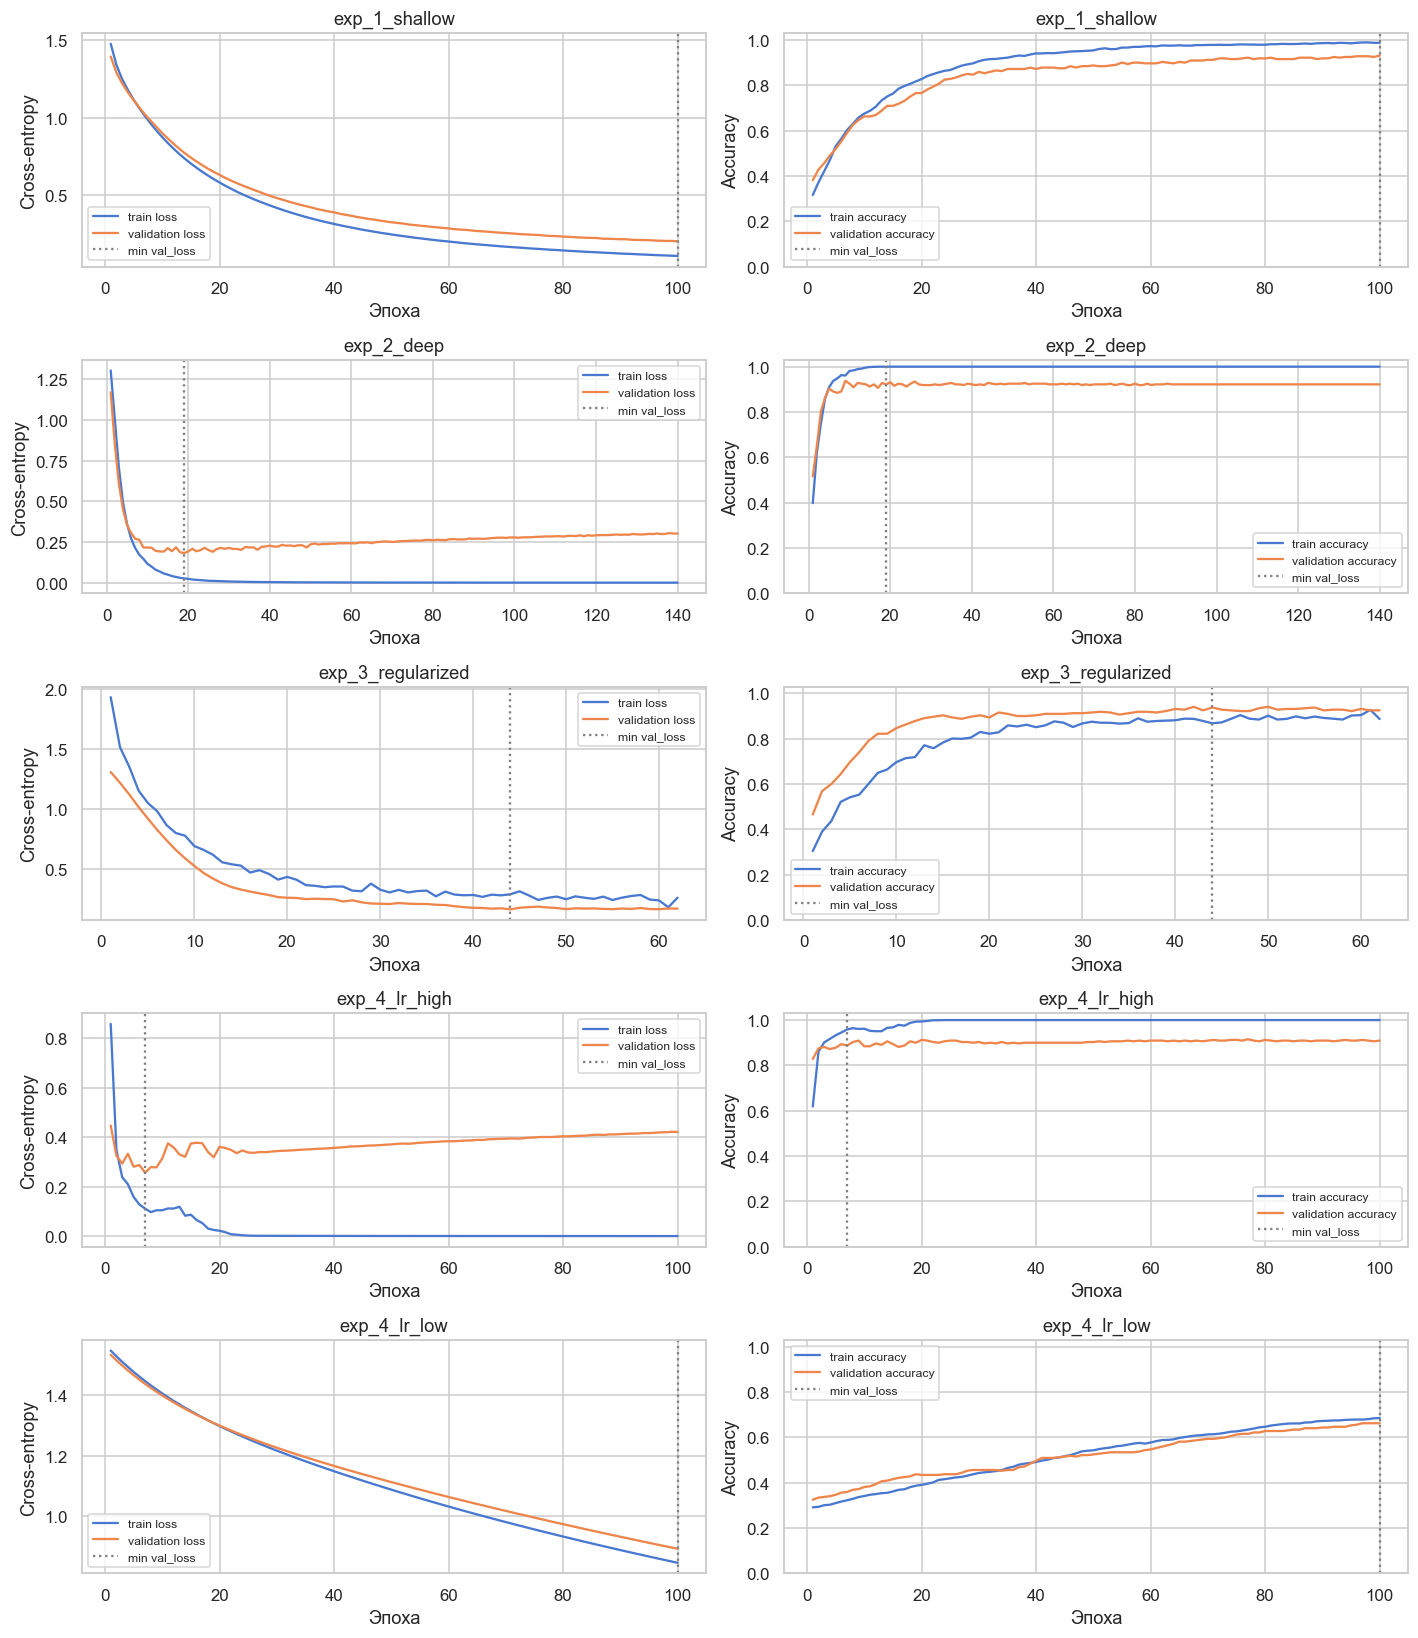

In [22]:
fig, axes = plt.subplots(len(histories), 2, figsize=(13, 3*len(histories)))
for (name, h), pair in zip(histories.items(), axes):
    epochs = np.arange(1, len(h["loss"])+1)
    pair[0].plot(epochs, h["loss"], label="train loss")
    pair[0].plot(epochs, h["val_loss"], label="validation loss")
    pair[1].plot(epochs, h["accuracy"], label="train accuracy")
    pair[1].plot(epochs, h["val_accuracy"], label="validation accuracy")
    pair[0].set(title=name, xlabel="Эпоха", ylabel="Cross-entropy")
    pair[1].set(title=name, xlabel="Эпоха", ylabel="Accuracy", ylim=(0, 1.03))
    for ax in pair:
        ax.axvline(np.argmin(h["val_loss"])+1, color="gray", linestyle=":", label="min val_loss")
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
deep = histories["exp_2_deep"]
deep_best = int(np.argmin(deep["val_loss"]))
# A sustained divergence requires five epochs above the previous best, lower train loss,
# and a new smoothed validation loss at least 0.01 above that previous best.
divergence = None
for i in range(5, len(deep["loss"])-4):
    prior_best = min(deep["val_loss"][:i])
    if (np.mean(deep["val_loss"][i:i+5]) > prior_best+0.01
        and min(deep["val_loss"][i:i+5]) > prior_best
        and np.mean(deep["loss"][i:i+5]) < np.mean(deep["loss"][i-5:i])):
        divergence = i+1
        break
reg = histories["exp_3_regularized"]
def trajectory_variation(h):
    return float(np.std(np.diff(h["val_loss"])))
ANALYSIS["nn_curves"] = (
    f"Exp 2: минимум val_loss={min(deep['val_loss']):.4f} на эпохе {deep_best+1}; "
    f"последние train/validation loss={deep['loss'][-1]:.4f}/{deep['val_loss'][-1]:.4f}. "
    + (f"Первый устойчивый сигнал расхождения по указанному в коде критерию — эпоха {divergence}. "
       if divergence else "Устойчивое расхождение по критерию пяти эпох не обнаружено. ")
    + f"Exp 3: минимум val_loss={min(reg['val_loss']):.4f}, выполнено {len(reg['loss'])} эпох. "
    f"Стандартное отклонение приращений val_loss: deep={trajectory_variation(deep):.4f}, "
    f"regularized={trajectory_variation(reg):.4f}. Dropout отключает случайную долю "
    "активаций на обучении, BatchNormalization использует батчевые статистики и накопленные "
    "оценки на валидации; поэтому train и validation loss измеряются в разных режимах. "
    "Регуляризация может улучшать обобщение, но её сглаживающий эффект не гарантирован: "
    "приведённая вариативность проверяет это по фактическим траекториям.")

### Интерпретация результатов

Exp 2: минимум val_loss=0.1816 на эпохе 19; последние train/validation loss=0.0001/0.3017. Первый устойчивый сигнал расхождения по указанному в коде критерию — эпоха 20. Exp 3: минимум val_loss=0.1681, выполнено 62 эпох. Стандартное отклонение приращений val_loss: deep=0.0381, regularized=0.0313. Dropout отключает случайную долю активаций на обучении, BatchNormalization использует батчевые статистики и накопленные оценки на валидации; поэтому train и validation loss измеряются в разных режимах. Регуляризация может улучшать обобщение, но её сглаживающий эффект не гарантирован: приведённая вариативность проверяет это по фактическим траекториям.

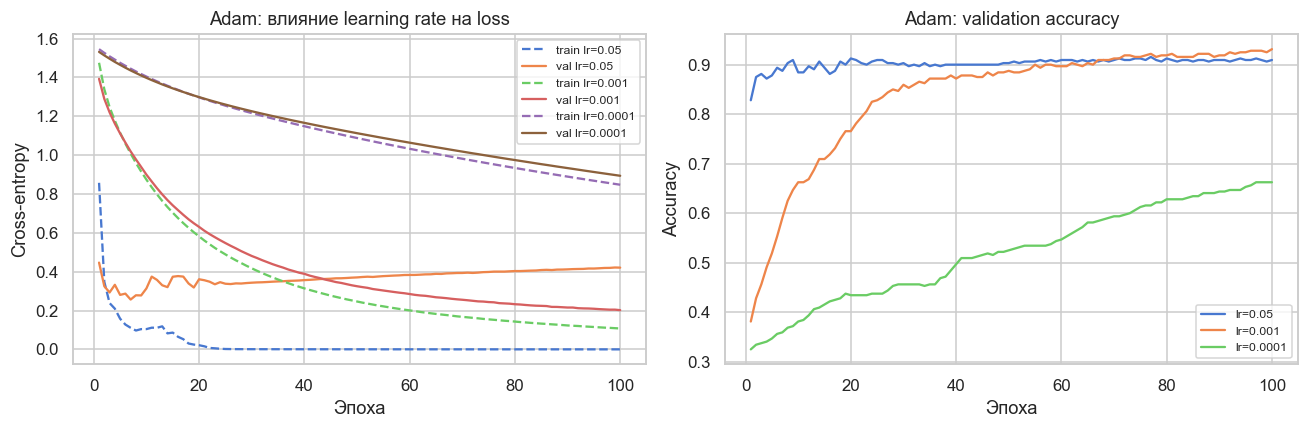

In [23]:
lr_runs = {0.05: "exp_4_lr_high", 0.001: "exp_1_shallow", 0.0001: "exp_4_lr_low"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr, name in lr_runs.items():
    h = histories[name]
    epochs = np.arange(1, len(h["loss"])+1)
    axes[0].plot(epochs, h["loss"], "--", label=f"train lr={lr}")
    axes[0].plot(epochs, h["val_loss"], label=f"val lr={lr}")
    axes[1].plot(epochs, h["val_accuracy"], label=f"lr={lr}")
axes[0].set(title="Adam: влияние learning rate на loss", xlabel="Эпоха", ylabel="Cross-entropy")
axes[1].set(title="Adam: validation accuracy", xlabel="Эпоха", ylabel="Accuracy")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
ANALYSIS["learning_rates"] = (
    "Контрольная архитектура 20→32→4, одинаковые 100 эпох и внутреннее разбиение. "
    + "; ".join(f"lr={lr}: min val_loss={min(histories[n]['val_loss']):.4f}, "
                  f"final val_accuracy={histories[n]['val_accuracy'][-1]:.4f}, "
                  f"std(Δval_loss)={trajectory_variation(histories[n]):.4f}" for lr,n in lr_runs.items())
    + ". Высокий шаг может приводить к перескокам через область минимума, малый — "
    "замедлять достижение низкой ошибки при фиксированном бюджете эпох. Adam адаптирует "
    "масштаб шага по моментам градиента, но не устраняет зависимость от learning rate. "
    "Оптимальное значение устанавливается по фактическому validation loss; lr=0.001 "
    "не объявляется лучшим заранее. Контроль этого lr повторно использует Exp 1.")

### Интерпретация результатов

Контрольная архитектура 20→32→4, одинаковые 100 эпох и внутреннее разбиение. lr=0.05: min val_loss=0.2567, final val_accuracy=0.9094, std(Δval_loss)=0.0187; lr=0.001: min val_loss=0.2020, final val_accuracy=0.9312, std(Δval_loss)=0.0167; lr=0.0001: min val_loss=0.8939, final val_accuracy=0.6625, std(Δval_loss)=0.0032. Высокий шаг может приводить к перескокам через область минимума, малый — замедлять достижение низкой ошибки при фиксированном бюджете эпох. Adam адаптирует масштаб шага по моментам градиента, но не устраняет зависимость от learning rate. Оптимальное значение устанавливается по фактическому validation loss; lr=0.001 не объявляется лучшим заранее. Контроль этого lr повторно использует Exp 1.

In [24]:
ipython = get_ipython()
original_cwd = Path.cwd()
try:
    # The literal relative magic also works on Windows when launched from ASCII staging.
    os.chdir(TB_WORKDIR)
    ipython.run_line_magic("load_ext", "tensorboard")  # %load_ext tensorboard
    ipython.run_line_magic("tensorboard", "--logdir logs/fit")  # %tensorboard --logdir logs/fit
except Exception as exc:
    print(f"Встраивание TensorBoard недоступно ({type(exc).__name__}).")
    print("Открыть отдельно: python -m tensorboard.main --logdir logs/fit")
finally:
    os.chdir(original_cwd)
print("Статические кривые сохранены в выходах предыдущих ячеек.")
ANALYSIS["tensorboard"] = (
    f"Для {len(histories)} уникальных запусков сформированы отдельные TensorBoard-логи "
    "с метриками и гистограммами весов. Выполнены magic-команды %load_ext tensorboard "
    "и %tensorboard --logdir logs/fit. Внешний просмотр: "
    "`python -m tensorboard.main --logdir logs/fit`. Встраивание зависит от среды Jupyter "
    "и браузера; все 4 ряда метрик loss/val_loss/accuracy/val_accuracy продублированы "
    "статическими изображениями из history.history, поэтому сохранённый отчёт "
    "содержит кривые и без работающего TensorBoard-сервера.")
if TB_WORKDIR != Path.cwd():
    ANALYSIS["tensorboard"] += (
        " В Windows при кириллице в пути события сначала записаны во временный ASCII-каталог, "
        "затем скопированы в logs/fit проекта. Сервер запущен из этого временного каталога "
        "для обхода ошибки файлового backend TensorFlow; сохранённые локальные логи остаются доступны.")

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

Статические кривые сохранены в выходах предыдущих ячеек.


### Интерпретация результатов

Для 5 уникальных запусков сформированы отдельные TensorBoard-логи с метриками и гистограммами весов. Выполнены magic-команды %load_ext tensorboard и %tensorboard --logdir logs/fit. Внешний просмотр: `python -m tensorboard.main --logdir logs/fit`. Встраивание зависит от среды Jupyter и браузера; все 4 ряда метрик loss/val_loss/accuracy/val_accuracy продублированы статическими изображениями из history.history, поэтому сохранённый отчёт содержит кривые и без работающего TensorBoard-сервера. В Windows при кириллице в пути события сначала записаны во временный ASCII-каталог, затем скопированы в logs/fit проекта. Сервер запущен из этого временного каталога для обхода ошибки файлового backend TensorFlow; сохранённые локальные логи остаются доступны.

,Accuracy,Precision,Recall,F1-macro,ROC-AUC
exp_3_regularized,0.93,0.9305,0.93,0.9293,0.9958


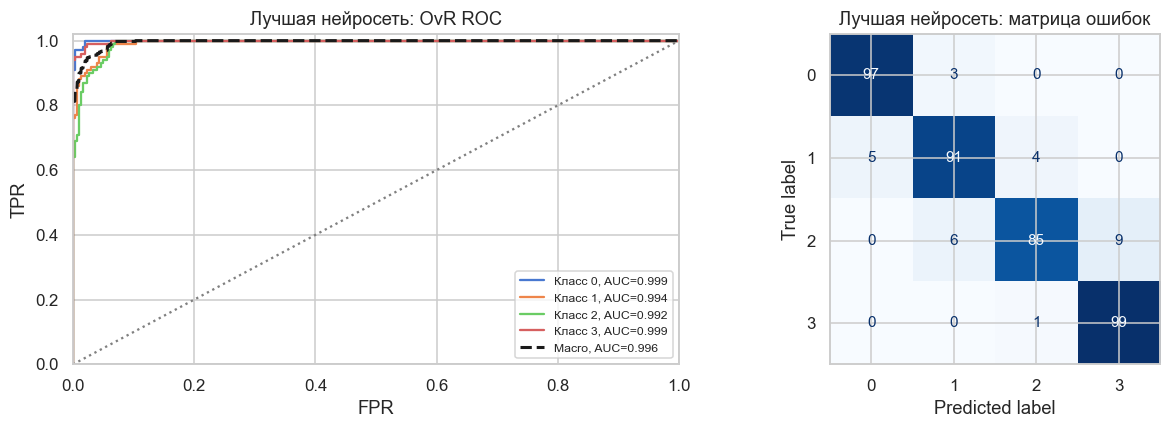

In [25]:
best_nn_name = nn_summary["min val_loss"].idxmin()
best_nn_config = configs[best_nn_name]
best_nn_epochs = int(nn_summary.loc[best_nn_name, "Лучшая эпоха"])
best_nn = build_network(best_nn_config)
refit_start = time.perf_counter()
best_nn.fit(make_dataset(X_train_scaled, y_train, training=True), epochs=best_nn_epochs, verbose=0)
nn_refit_seconds = time.perf_counter() - refit_start
nn_proba = best_nn(tf.convert_to_tensor(X_test_scaled, dtype=tf.float32), training=False).numpy()
nn_pred = nn_proba.argmax(axis=1)
nn_metrics = metrics(y_test, nn_pred, nn_proba)
display(pd.DataFrame([nn_metrics], index=[best_nn_name]).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nn_aucs = plot_roc(y_test, nn_proba, axes[0], "Лучшая нейросеть: OvR ROC")
nn_cm = confusion_matrix(y_test, nn_pred, labels=CLASSES)
ConfusionMatrixDisplay(nn_cm, display_labels=CLASSES).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Лучшая нейросеть: матрица ошибок")
plt.tight_layout(); plt.show()
best_nn.save(ARTIFACTS / "best_neural_network.keras")
ANALYSIS["nn_final"] = (
    f"По внутреннему val_loss выбрана {best_nn_name}, число эпох для refit={best_nn_epochs}. "
    "Модель обучена с нуля на всём внешнем train с импутером/скейлером, обученными "
    "только на нём. Тест не использован ни для выбора архитектуры, ни для остановки. "
    + "; ".join(f"{k}={v:.4f}" for k,v in nn_metrics.items())
    + f". Ошибок {int((nn_pred != y_test).sum())}/{len(y_test)}, "
    f"между соседними классами {int((np.abs(nn_pred-y_test.to_numpy()) == 1).sum())}, "
    f"между 0 и 3 — {int(nn_cm[0,3]+nn_cm[3,0])}. "
    "Переобучение на всех 1600 объектах меняет траекторию, поэтому validation-качество "
    "и тестовое качество refit-модели не обязаны совпадать. Сохранённая Keras-модель "
    "принимает стандартизованные признаки; для сырых данных нужны сохранённые параметры предобработки.")

### Интерпретация результатов

По внутреннему val_loss выбрана exp_3_regularized, число эпох для refit=44. Модель обучена с нуля на всём внешнем train с импутером/скейлером, обученными только на нём. Тест не использован ни для выбора архитектуры, ни для остановки. Accuracy=0.9300; Precision=0.9305; Recall=0.9300; F1-macro=0.9293; ROC-AUC=0.9958. Ошибок 28/400, между соседними классами 28, между 0 и 3 — 0. Переобучение на всех 1600 объектах меняет траекторию, поэтому validation-качество и тестовое качество refit-модели не обязаны совпадать. Сохранённая Keras-модель принимает стандартизованные признаки; для сырых данных нужны сохранённые параметры предобработки.

## 8. Финальное сравнение и выводы

,Accuracy,Precision,Recall,F1-macro,ROC-AUC
SVM,0.9750,0.97505,0.9750,0.97500,0.99936
LDA,0.9550,0.95561,0.9550,0.95518,0.99582
TensorFlow MLP,0.9300,0.93052,0.9300,0.92926,0.99578
DecisionTree,0.8750,0.87381,0.8750,0.87416,0.96698
GaussianNB,0.8225,0.82081,0.8225,0.82141,0.95241
kNN,0.7300,0.73153,0.7300,0.73057,0.89163


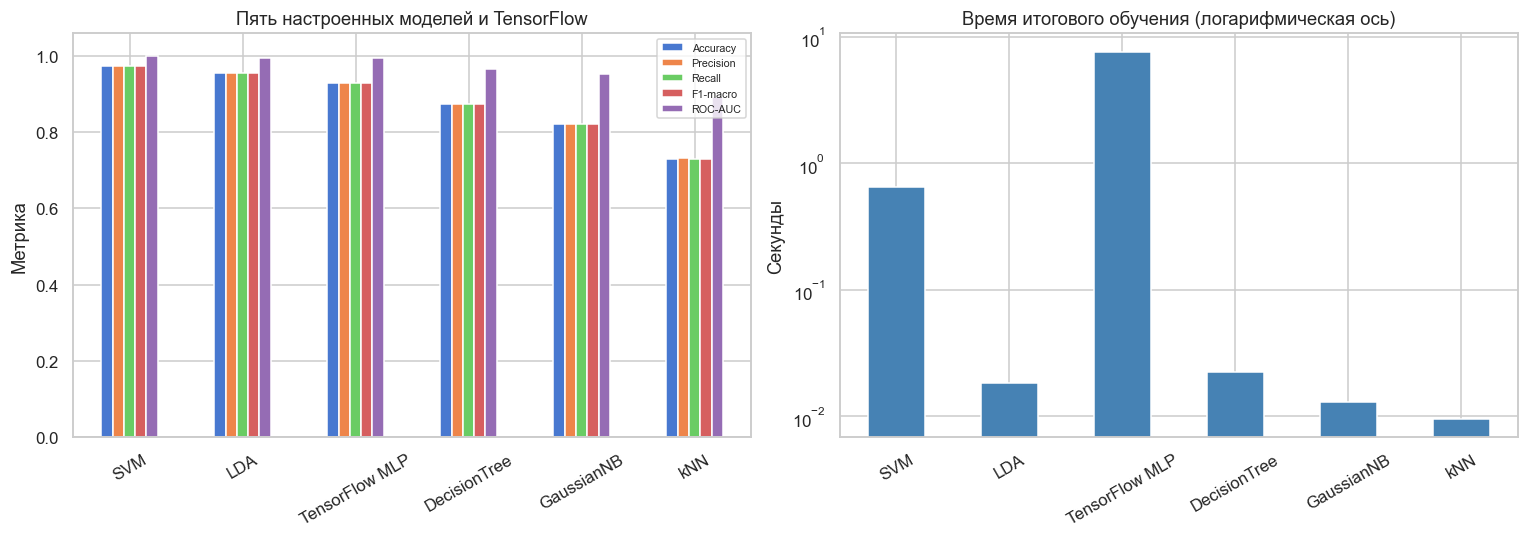

In [26]:
final = tuned.copy()
final.loc["TensorFlow MLP"] = nn_metrics
final = final.sort_values(["F1-macro", "ROC-AUC"], ascending=False)
display(final.round(5))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
final[METRICS].plot.bar(ax=axes[0], rot=30)
axes[0].set(title="Пять настроенных моделей и TensorFlow", ylabel="Метрика", ylim=(0, 1.06))
axes[0].legend(fontsize=7)
refit_times = {n:s.refit_time_ for n,s in searches.items()}
refit_times["TensorFlow MLP"] = nn_refit_seconds
pd.Series(refit_times).reindex(final.index).plot.bar(ax=axes[1], rot=30, logy=True, color="steelblue")
axes[1].set(title="Время итогового обучения (логарифмическая ось)", ylabel="Секунды")
plt.tight_layout(); plt.show()
winner = final.index[0]
ml_best = tuned["F1-macro"].idxmax()
nn_delta = nn_metrics["F1-macro"] - tuned.loc[ml_best,"F1-macro"]
ANALYSIS["final"] = (
    f"В описательном рейтинге тестового F1 лидирует {winner}: F1-macro="
    f"{final.iloc[0]['F1-macro']:.4f}, ROC-AUC={final.iloc[0]['ROC-AUC']:.4f}. "
    f"Лучший классический результат у {ml_best} (F1={tuned.loc[ml_best,'F1-macro']:.4f}); "
    f"TensorFlow F1={nn_metrics['F1-macro']:.4f}, разница {100*nn_delta:+.2f} п.п. "
    f"LDA: F1={tuned.loc['LDA','F1-macro']:.4f}, SVM: {tuned.loc['SVM','F1-macro']:.4f}. "
    f"Refit LDA занял {refit_times['LDA']:.3f} с, SVM — {refit_times['SVM']:.3f} с, "
    f"нейросети — {nn_refit_seconds:.3f} с. Суммарный поиск классических моделей занял "
    f"{sum(search_times.values()):.1f} с, серия нейросетевых экспериментов — {sum(nn_times.values()):.1f} с. "
    "Refit-время и стоимость поиска разделены; замеры на одном CPU не являются универсальным "
    "бенчмарком. Сильный сигнал RAM помогает компактным линейным моделям; MLP дополнительно "
    "нуждается в выборе архитектуры, шага и числа эпох. Для этого набора разумно сопоставлять "
    "достигнутый F1 с указанной стоимостью, не предполагая превосходства глубокой сети. "
    "Один тест из 400 объектов не позволяет утверждать статистическую значимость небольших "
    "различий: одна ошибка меняет Accuracy на 0.25 п.п. Рейтинг не заменяет повторную "
    "валидацию на других разбиениях или новых данных.")

# Export reusable raw-data inference pipelines and a machine-readable experiment report.
import joblib
joblib.dump(tuned_models, ARTIFACTS / "classical_pipelines.joblib")
joblib.dump({"imputer": imputer, "scaler": standard_scaler, "features": FEATURES,
             "classes": CLASSES}, ARTIFACTS / "neural_preprocessing.joblib")
final.to_csv(ARTIFACTS / "final_metrics.csv", encoding="utf-8-sig")
for name, h in histories.items():
    pd.DataFrame(h).to_csv(ARTIFACTS / f"{name}_history.csv", index_label="epoch_zero_based")
report = {"versions": versions, "random_state": RANDOM_STATE, "dataset_sha256": dataset_sha256,
    "baseline": baseline.to_dict(orient="index"), "tuned": tuned.to_dict(orient="index"),
    "final": final.to_dict(orient="index"), "best_nn": best_nn_name, "best_nn_epochs": best_nn_epochs,
    "search_seconds": search_times, "nn_seconds": nn_times, "nn_refit_seconds": nn_refit_seconds,
    "best_params": {n:s.best_params_ for n,s in searches.items()},
    "cv_f1": {n:s.best_score_ for n,s in searches.items()}, "nn_logs": nn_log_dirs}
(ARTIFACTS / "experiment_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2, default=lambda x: x.item()), encoding="utf-8")
assert final.shape == (6, 5) and final.notna().all().all()
assert ((final >= 0) & (final <= 1)).all().all()
assert len(searches) == 5 and len(histories) == 5
assert all(len(s.cv_results_["params"]) == expected for s, expected in
           zip(searches.values(), [20, 160, 23, 60, 160]))
display({"application/vnd.lab2.analysis+json": ANALYSIS}, raw=True)

### Интерпретация результатов

В описательном рейтинге тестового F1 лидирует SVM: F1-macro=0.9750, ROC-AUC=0.9994. Лучший классический результат у SVM (F1=0.9750); TensorFlow F1=0.9293, разница -4.57 п.п. LDA: F1=0.9552, SVM: 0.9750. Refit LDA занял 0.018 с, SVM — 0.647 с, нейросети — 7.641 с. Суммарный поиск классических моделей занял 191.0 с, серия нейросетевых экспериментов — 133.9 с. Refit-время и стоимость поиска разделены; замеры на одном CPU не являются универсальным бенчмарком. Сильный сигнал RAM помогает компактным линейным моделям; MLP дополнительно нуждается в выборе архитектуры, шага и числа эпох. Для этого набора разумно сопоставлять достигнутый F1 с указанной стоимостью, не предполагая превосходства глубокой сети. Один тест из 400 объектов не позволяет утверждать статистическую значимость небольших различий: одна ошибка меняет Accuracy на 0.25 п.п. Рейтинг не заменяет повторную валидацию на других разбиениях или новых данных.

### Источники и воспроизведение

- [Mobile Price Classification, исходный набор](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification).
- [KaggleHub: загрузка и кеширование наборов](https://github.com/Kaggle/kagglehub).
- [scikit-learn: предотвращение утечки данных через Pipeline](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [MinMaxScaler: поведение clip на новых наблюдениях](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).
- [TensorFlow: TensorBoard callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/TensorBoard).

`requirements-lock.txt` фиксирует версии выполненного окружения. Каталог `artifacts/`
содержит таблицы, истории, JSON-отчёт, классические Pipeline и нейросеть с отдельным
препроцессором; `logs/fit/` содержит TensorBoard-события. Они создаются заново при запуске.
Для обновления чисел в Markdown после изменения кода или данных используйте генератор.
Сохранённые Markdown-выводы относятся к конкретному выполнению и SHA-256 набора выше.